In [1]:
import numpy as np
import pandas as pd
import gc
import time
import re
import pickle
import os
from collections import Counter
from scipy.sparse import hstack
from sklearn import model_selection
from datetime import datetime
from contextlib import contextmanager
from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import KFold, StratifiedKFold
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

dataPath = "/new_dataset/raw/"

In [3]:
@contextmanager
def timer(title):
    t0 = time.time()
    yield
    print("{} - done in {:.0f}s".format(title, time.time() - t0))
def clean_column_names(df):
    def clean_name(name):
        # Chỉ giữ lại chữ cái, số và dấu gạch dưới
        return re.sub(r'[^A-Za-z0-9_]', '_', name)
    df.columns = [clean_name(col) for col in df.columns]
    return df
def reduce_memory_usage(df):

    start_mem = df.memory_usage().sum() / 1024**2
    print('Memory usage of dataframe is {:.2f} MB'.format(start_mem))

    for col in df.columns:
        col_type = df[col].dtype

        if col_type != object:
            c_min = df[col].min()
            c_max = df[col].max()
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)
            else:
                if c_min > np.finfo(np.float16).min and c_max < np.finfo(np.float16).max:
                    df[col] = df[col].astype(np.float16)
                elif c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)

    end_mem = df.memory_usage().sum() / 1024**2
    print('Memory usage after optimization is: {:.2f} MB'.format(end_mem))
    print('Decreased by {:.1f}%'.format(100 * (start_mem - end_mem) / start_mem))

    return df
bureau_data = reduce_memory_usage(pd.read_csv(dataPath+'bureau.csv', nrows = None))
bureau_balance = reduce_memory_usage(pd.read_csv(dataPath + 'bureau_balance.csv', nrows = None))
application_train = reduce_memory_usage(pd.read_csv(dataPath + 'application_train.csv', nrows = None))
application_test = reduce_memory_usage(pd.read_csv(dataPath + 'application_test.csv', nrows = None))
credit_card_balance = reduce_memory_usage(pd.read_csv(dataPath + 'credit_card_balance.csv', nrows = None))
installments_payments = reduce_memory_usage(pd.read_csv(dataPath + 'installments_payments.csv', nrows = None))
pos_cash_balance = reduce_memory_usage(pd.read_csv(dataPath + 'POS_CASH_balance.csv', nrows = None))
previous_application = reduce_memory_usage(pd.read_csv(dataPath + 'previous_application.csv', nrows = None))

FileNotFoundError: [Errno 2] No such file or directory: '/new_dataset/raw/bureau.csv'

In [ ]:
application_test['TARGET'] = np.nan  # Quan trọng để có test_df!
application_train_test = pd.concat([application_train, application_test], ignore_index=True)

/tmp/ipykernel_99225/1105884486.py:1: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`



In [ ]:
print('Size of application_train data', application_train_test.shape)
print('Size of POS_CASH_balance data', pos_cash_balance.shape)
print('Size of bureau_balance data', bureau_balance.shape)
print('Size of previous_application data', previous_application.shape)
print('Size of installments_payments data', installments_payments.shape)
print('Size of credit_card_balance data', credit_card_balance.shape)
print('Size of bureau data', bureau_data.shape)

Size of application_train data (356255, 122)
Size of POS_CASH_balance data (10001358, 8)
Size of bureau_balance data (27299925, 3)
Size of previous_application data (1670214, 37)
Size of installments_payments data (13605401, 8)
Size of credit_card_balance data (3840312, 23)
Size of bureau data (1716428, 17)


In [ ]:
# Lấy danh sách khách hàng có previous application
customers_with_prev = previous_application['SK_ID_CURR'].unique()

In [ ]:
# Tách 2 nhóm
app_has_prev = application_train_test[application_train_test['SK_ID_CURR'].isin(customers_with_prev)].copy()
app_no_prev = application_train_test[~application_train_test['SK_ID_CURR'].isin(customers_with_prev)].copy()

In [ ]:
# In số lượng khách hàng mỗi nhóm
print("Số khách hàng CÓ previous application:", app_has_prev.shape[0])
print("Số khách hàng KHÔNG CÓ previous application:", app_no_prev.shape[0])

Số khách hàng CÓ previous application: 338857
Số khách hàng KHÔNG CÓ previous application: 17398


In [ ]:
from sklearn.preprocessing import LabelEncoder

def label_encode_dataframe(df):
    """
    Label encode all object (categorical) columns in a DataFrame.

    Parameters:
        df (pd.DataFrame): Input DataFrame.

    Returns:
        pd.DataFrame: DataFrame with label encoded categorical columns.
    """
    df = df.copy()
    cat_cols = [col for col in df.columns if df[col].dtype == 'object']
    print(f"Encoding {len(cat_cols)} categorical columns: {cat_cols}")

    for col in cat_cols:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))

    return df

In [ ]:
def application_train_test(df, num_rows=None):
    df = df[df['CODE_GENDER'] != 'XNA']
    df['DAYS_EMPLOYED'].replace(365243, np.nan, inplace=True)
    df['DAYS_EMPLOYED_PERC'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']
    df['INCOME_CREDIT_PERC'] = df['AMT_INCOME_TOTAL'] / df['AMT_CREDIT']
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
    df['ANNUITY_INCOME_PERC'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['PAYMENT_RATE'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    gc.collect()
    return df


In [ ]:
def bureau_and_balance(bureau,bb, num_rows=None):
    # Chỉ dùng numeric features
    bb_agg = bb.groupby('SK_ID_BUREAU')['MONTHS_BALANCE'].agg(['min', 'max', 'size'])
    bb_agg.columns = ['MONTHS_BALANCE_MIN', 'MONTHS_BALANCE_MAX', 'MONTHS_BALANCE_SIZE']
    bureau = bureau.join(bb_agg, how='left', on='SK_ID_BUREAU')
    bureau.drop(['SK_ID_BUREAU'], axis=1, inplace=True)

    num_agg = {
        'DAYS_CREDIT': ['min', 'max', 'mean', 'var'],
        'DAYS_CREDIT_ENDDATE': ['min', 'max', 'mean'],
        'DAYS_CREDIT_UPDATE': ['mean'],
        'CREDIT_DAY_OVERDUE': ['max', 'mean'],
        'AMT_CREDIT_MAX_OVERDUE': ['mean'],
        'AMT_CREDIT_SUM': ['max', 'mean', 'sum'],
        'AMT_CREDIT_SUM_DEBT': ['max', 'mean', 'sum'],
        'AMT_CREDIT_SUM_OVERDUE': ['mean'],
        'AMT_CREDIT_SUM_LIMIT': ['mean', 'sum'],
        'AMT_ANNUITY': ['max', 'mean'],
        'CNT_CREDIT_PROLONG': ['sum'],
        'MONTHS_BALANCE_MIN': ['min'],
        'MONTHS_BALANCE_MAX': ['max'],
        'MONTHS_BALANCE_SIZE': ['mean', 'sum']
    }

    bureau_agg = bureau.groupby('SK_ID_CURR').agg(num_agg)
    bureau_agg.columns = ['BURO_' + '_'.join(col).upper() for col in bureau_agg.columns]

    gc.collect()
    return bureau_agg

In [ ]:
def previous(prev, num_rows=None):
    #prev = pd.read_csv('../input/previous_application.csv', nrows=num_rows)
    prev.replace(365243, np.nan, inplace=True)
    prev['APP_CREDIT_PERC'] = prev['AMT_APPLICATION'] / prev['AMT_CREDIT']

    num_agg = {
        'AMT_ANNUITY': ['min', 'max', 'mean'],
        'AMT_APPLICATION': ['min', 'max', 'mean'],
        'AMT_CREDIT': ['min', 'max', 'mean'],
        'APP_CREDIT_PERC': ['min', 'max', 'mean', 'var'],
        'AMT_DOWN_PAYMENT': ['min', 'max', 'mean'],
        'AMT_GOODS_PRICE': ['min', 'max', 'mean'],
        'HOUR_APPR_PROCESS_START': ['min', 'max', 'mean'],
        'RATE_DOWN_PAYMENT': ['min', 'max', 'mean'],
        'DAYS_DECISION': ['min', 'max', 'mean'],
        'CNT_PAYMENT': ['mean', 'sum']
    }

    prev_agg = prev.groupby('SK_ID_CURR').agg(num_agg)
    prev_agg.columns = ['PREV_' + '_'.join(col).upper() for col in prev_agg.columns]
    gc.collect()
    return prev_agg


In [ ]:
def pos_cash(pos, num_rows=None):
    #pos = pd.read_csv('../input/POS_CASH_balance.csv', nrows=num_rows)
    agg = {
        'MONTHS_BALANCE': ['max', 'mean', 'size'],
        'SK_DPD': ['max', 'mean'],
        'SK_DPD_DEF': ['max', 'mean']
    }
    pos_agg = pos.groupby('SK_ID_CURR').agg(agg)
    pos_agg.columns = ['POS_' + '_'.join(col).upper() for col in pos_agg.columns]
    pos_agg['POS_COUNT'] = pos.groupby('SK_ID_CURR').size()
    gc.collect()
    return pos_agg

In [ ]:
def installment(ins, num_rows=None):
    #ins = pd.read_csv('../input/installments_payments.csv', nrows=num_rows)
    ins['PAYMENT_PERC'] = ins['AMT_PAYMENT'] / ins['AMT_INSTALMENT']
    ins['PAYMENT_DIFF'] = ins['AMT_INSTALMENT'] - ins['AMT_PAYMENT']
    ins['DPD'] = (ins['DAYS_ENTRY_PAYMENT'] - ins['DAYS_INSTALMENT']).clip(lower=0)
    ins['DBD'] = (ins['DAYS_INSTALMENT'] - ins['DAYS_ENTRY_PAYMENT']).clip(lower=0)

    agg = {
        'NUM_INSTALMENT_VERSION': ['nunique'],
        'DPD': ['max', 'mean', 'sum'],
        'DBD': ['max', 'mean', 'sum'],
        'PAYMENT_PERC': ['max', 'mean', 'sum', 'var'],
        'PAYMENT_DIFF': ['max', 'mean', 'sum', 'var'],
        'AMT_INSTALMENT': ['max', 'mean', 'sum'],
        'AMT_PAYMENT': ['min', 'max', 'mean', 'sum'],
        'DAYS_ENTRY_PAYMENT': ['max', 'mean', 'sum']
    }

    ins_agg = ins.groupby('SK_ID_CURR').agg(agg)
    ins_agg.columns = ['INST_' + '_'.join(col).upper() for col in ins_agg.columns]
    gc.collect()
    return ins_agg


In [ ]:
# Preprocess credit_card_balance.csv
def credit_card(cc, num_rows = None, nan_as_category = True):
    #cc = pd.read_csv('../input/credit_card_balance.csv', nrows = num_rows)
    #cc, cat_cols = one_hot_encoder(cc, nan_as_category= True)
    # General aggregations
    cc =label_encode_dataframe(cc)
    cc_agg = cc.groupby('SK_ID_CURR').agg(['min', 'max', 'mean', 'sum', 'var'])
    cc_agg.columns = pd.Index(['CC_' + e[0] + "_" + e[1].upper() for e in cc_agg.columns.tolist()])
    # Count credit card lines
    cc_agg['CC_COUNT'] = cc.groupby('SK_ID_CURR').size()
    del cc
    gc.collect()
    return cc_agg

# Phân tích chung tất cả data

## Merge data

In [ ]:
# Bật/tắt chế độ debug
debug = False
num_rows = 10000 if debug else None
# Dùng tập này làm tập chính
df = app_has_prev.copy()

# Bureau + bureau_balance
bureau_agg = bureau_and_balance(bureau_data, bureau_balance, num_rows)
print("Bureau df shape:", bureau_agg.shape)
df = df.join(bureau_agg, how='left', on='SK_ID_CURR')

# Previous applications
prev_agg = previous(previous_application, num_rows)
print("Previous applications df shape:", prev_agg.shape)
df = df.join(prev_agg, how='left', on='SK_ID_CURR')

# POS_CASH_balance
pos_agg = pos_cash(pos_cash_balance, num_rows)
print("POS-CASH balance df shape:", pos_agg.shape)
df = df.join(pos_agg, how='left', on='SK_ID_CURR')

# Join với bảng installments_payments
ins = installment(installments_payments,num_rows)
print("Installments payments df shape:", ins.shape)
df = df.join(ins, how='left', on='SK_ID_CURR')

# Credit card balance
cc_agg = credit_card(credit_card_balance, num_rows)
print("Credit card balance df shape:", cc_agg.shape)
df = df.join(cc_agg, how='left', on='SK_ID_CURR')

Bureau df shape: (305811, 27)


/home/jupyter-iec_roadquality/.local/lib/python3.10/site-packages/pandas/core/dtypes/cast.py:1860: RuntimeWarning:

overflow encountered in cast



Previous applications df shape: (338856, 30)
POS-CASH balance df shape: (337252, 8)
Installments payments df shape: (339587, 25)
Encoding 1 categorical columns: ['NAME_CONTRACT_STATUS']
Credit card balance df shape: (103558, 111)


In [ ]:
# In kích thước tổng thể của dataframe cuối cùng
print("Final dataframe shape:", df.shape)

Final dataframe shape: (338857, 323)


## Find important features

In [ ]:
from sklearn.model_selection import KFold
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

def kfold_lightgbm(train_df, test_df=None, num_folds=5, stratified=False, debug=False):
    print("Starting LightGBM. Train shape: {}, test shape: {}".format(train_df.shape, test_df.shape if test_df is not None else "None"))

    feats = [f for f in train_df.columns if f not in ['TARGET', 'SK_ID_CURR']]
    train_df = df_encode[df_encode['TARGET'].notnull()]
    target = train_df['TARGET']
    train_df = train_df.drop(columns=['TARGET'])


    folds = KFold(n_splits=num_folds, shuffle=True, random_state=47)

    oof_preds = np.zeros(train_df.shape[0])
    sub_preds = np.zeros(test_df.shape[0]) if test_df is not None and not test_df.empty else None

    feature_importance_df = pd.DataFrame()

    for n_fold, (train_idx, valid_idx) in enumerate(folds.split(train_df[feats], target)):
        print(f"Fold {n_fold + 1}")
        train_x, train_y = train_df[feats].iloc[train_idx], target.iloc[train_idx]
        valid_x, valid_y = train_df[feats].iloc[valid_idx], target.iloc[valid_idx]

        clf = LGBMClassifier(
            n_estimators=10000,
            learning_rate=0.02,
            num_leaves=34,
            colsample_bytree=0.9497036,
            subsample=0.8715623,
            max_depth=8,
            reg_alpha=0.041545473,
            reg_lambda=0.0735294,
            min_split_gain=0.0222415,
            min_child_weight=39.3259775,
            silent=-1,
            verbose=-1,
            random_state=47,
            n_jobs=-1
        )

        clf.fit(train_x, train_y,
                eval_set=[(train_x, train_y), (valid_x, valid_y)],
                eval_metric='auc',
                callbacks=[
                    early_stopping(stopping_rounds=200),
                    log_evaluation(period=200)
                ])

        oof_preds[valid_idx] = clf.predict_proba(valid_x, num_iteration=clf.best_iteration_)[:, 1]

        if sub_preds is not None:
            sub_preds += clf.predict_proba(test_df[feats], num_iteration=clf.best_iteration_)[:, 1] / folds.n_splits

        fold_importance_df = pd.DataFrame()
        fold_importance_df["feature"] = feats
        fold_importance_df["importance"] = clf.feature_importances_
        fold_importance_df["fold"] = n_fold + 1
        feature_importance_df = pd.concat([feature_importance_df, fold_importance_df], axis=0)

    print('Full AUC score %.6f' % roc_auc_score(target, oof_preds))

    if not debug:
        if sub_preds is not None:
            submission = test_df[['SK_ID_CURR']].copy()
            submission['TARGET'] = sub_preds
            submission.to_csv('submission_lgb.csv', index=False)

    return feature_importance_df


In [ ]:
# Display/plot feature importance
def display_importances(feature_importance_df_):
    cols = feature_importance_df_[["feature", "importance"]].groupby("feature").mean().sort_values(by="importance", ascending=False)[:40].index
    best_features = feature_importance_df_.loc[feature_importance_df_.feature.isin(cols)]
    plt.figure(figsize=(8, 10))
    sns.barplot(x="importance", y="feature", data=best_features.sort_values(by="importance", ascending=False))
    plt.title('LightGBM Features (avg over folds)')
    plt.tight_layout()
    plt.savefig('lgbm_importances01.png')


In [ ]:
df_encode = label_encode_dataframe(df)
df_encode.head()

Encoding 16 categorical columns: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,CC_SK_DPD_MAX,CC_SK_DPD_MEAN,CC_SK_DPD_SUM,CC_SK_DPD_VAR,CC_SK_DPD_DEF_MIN,CC_SK_DPD_DEF_MAX,CC_SK_DPD_DEF_MEAN,CC_SK_DPD_DEF_SUM,CC_SK_DPD_DEF_VAR,CC_COUNT
0,100002,1.0,0,1,0,1,0,202500.0,406597.5,24700.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100003,0.0,0,0,0,0,0,270000.0,1293502.5,35698.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0.0,1,1,1,1,0,67500.0,135000.0,6750.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100006,0.0,0,0,0,1,0,135000.0,312682.5,29686.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0
4,100007,0.0,0,1,0,1,0,121500.0,513000.0,21865.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(df_encode['TARGET'].isnull().sum())
print(df_encode['TARGET'].value_counts(dropna=False))


47800
TARGET
0.0    267212
NaN     47800
1.0     23845
Name: count, dtype: int64


In [ ]:
feat_importance = kfold_lightgbm(df_encode, num_folds= 10, stratified= False, debug= debug)

Starting LightGBM. Train shape: (338857, 323), test shape: None
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.792585	training's binary_logloss: 0.239065	valid_1's auc: 0.764361	valid_1's binary_logloss: 0.249705
[400]	training's auc: 0.813852	training's binary_logloss: 0.230116	valid_1's auc: 0.772541	valid_1's binary_logloss: 0.246326
[600]	training's auc: 0.82878	training's binary_logloss: 0.224169	valid_1's auc: 0.775214	valid_1's binary_logloss: 0.245292
[800]	training's auc: 0.840277	training's binary_logloss: 0.219524	valid_1's auc: 0.776458	valid_1's binary_logloss: 0.2449
[1000]	training's auc: 0.850105	training's binary_logloss: 0.21545	valid_1's auc: 0.777099	valid_1's binary_logloss: 0.244667
[1200]	training's auc: 0.859118	training's binary_logloss: 0.211647	valid_1's auc: 0.777294	valid_1's binary_logloss: 0.244652
[1400]	training's auc: 0.867209	training's binary_logloss: 0.208077	valid_1's auc: 0.77732	valid_1's binary_loglo

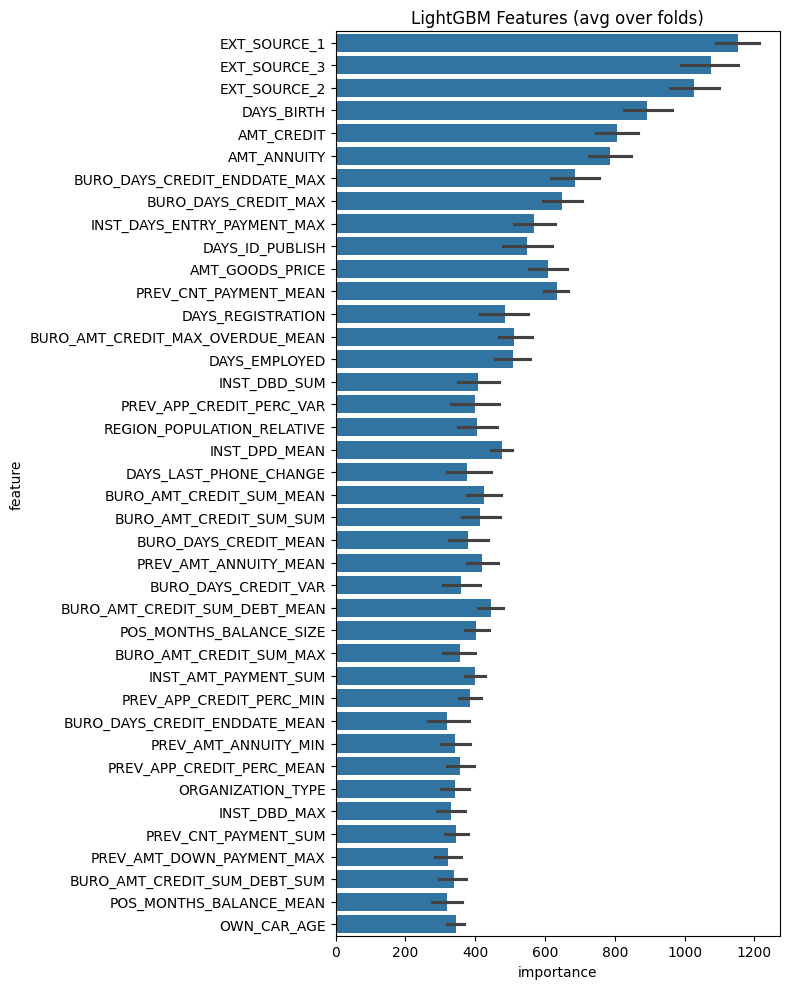

In [ ]:
display_importances(feat_importance)

In [ ]:
important_features = (
    feat_importance.groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
)

print("Danh sách các feature quan trọng giảm dần:")
for i, f in enumerate(important_features.index.tolist()):
    print(f"{i+1}. {f}")


Danh sách các feature quan trọng giảm dần:
1. EXT_SOURCE_1
2. EXT_SOURCE_3
3. EXT_SOURCE_2
4. DAYS_BIRTH
5. AMT_CREDIT
6. AMT_ANNUITY
7. BURO_DAYS_CREDIT_ENDDATE_MAX
8. BURO_DAYS_CREDIT_MAX
9. PREV_CNT_PAYMENT_MEAN
10. AMT_GOODS_PRICE
11. INST_DAYS_ENTRY_PAYMENT_MAX
12. DAYS_ID_PUBLISH
13. BURO_AMT_CREDIT_MAX_OVERDUE_MEAN
14. DAYS_EMPLOYED
15. DAYS_REGISTRATION
16. INST_DPD_MEAN
17. BURO_AMT_CREDIT_SUM_DEBT_MEAN
18. BURO_AMT_CREDIT_SUM_MEAN
19. PREV_AMT_ANNUITY_MEAN
20. BURO_AMT_CREDIT_SUM_SUM
21. INST_DBD_SUM
22. REGION_POPULATION_RELATIVE
23. POS_MONTHS_BALANCE_SIZE
24. PREV_APP_CREDIT_PERC_VAR
25. INST_AMT_PAYMENT_SUM
26. PREV_APP_CREDIT_PERC_MIN
27. BURO_DAYS_CREDIT_MEAN
28. DAYS_LAST_PHONE_CHANGE
29. BURO_DAYS_CREDIT_VAR
30. PREV_APP_CREDIT_PERC_MEAN
31. BURO_AMT_CREDIT_SUM_MAX
32. PREV_CNT_PAYMENT_SUM
33. OWN_CAR_AGE
34. PREV_AMT_ANNUITY_MIN
35. ORGANIZATION_TYPE
36. BURO_AMT_CREDIT_SUM_DEBT_SUM
37. INST_DBD_MAX
38. PREV_AMT_DOWN_PAYMENT_MAX
39. POS_MONTHS_BALANCE_MEAN
40. BURO_D

## Phân tích top 100 feature quan trọng

In [ ]:
from collections import Counter

# Danh sách 100 feature quan trọng đầu tiên
top100_feats = [
    "EXT_SOURCE_1", "EXT_SOURCE_3", "EXT_SOURCE_2", "DAYS_BIRTH", "AMT_CREDIT", "AMT_ANNUITY",
    "BURO_DAYS_CREDIT_ENDDATE_MAX", "BURO_DAYS_CREDIT_MAX", "PREV_CNT_PAYMENT_MEAN", "AMT_GOODS_PRICE",
    "INST_DAYS_ENTRY_PAYMENT_MAX", "DAYS_ID_PUBLISH", "BURO_AMT_CREDIT_MAX_OVERDUE_MEAN", "DAYS_EMPLOYED",
    "INST_DPD_MEAN", "DAYS_REGISTRATION", "BURO_AMT_CREDIT_SUM_DEBT_MEAN", "BURO_AMT_CREDIT_SUM_MEAN",
    "PREV_AMT_ANNUITY_MEAN", "POS_MONTHS_BALANCE_SIZE", "INST_DBD_SUM", "BURO_AMT_CREDIT_SUM_SUM",
    "INST_AMT_PAYMENT_SUM", "PREV_APP_CREDIT_PERC_MIN", "REGION_POPULATION_RELATIVE", "PREV_APP_CREDIT_PERC_VAR",
    "BURO_DAYS_CREDIT_MEAN", "DAYS_LAST_PHONE_CHANGE", "BURO_AMT_CREDIT_SUM_MAX", "PREV_CNT_PAYMENT_SUM",
    "BURO_DAYS_CREDIT_VAR", "OWN_CAR_AGE", "PREV_APP_CREDIT_PERC_MEAN", "PREV_AMT_ANNUITY_MIN",
    "BURO_AMT_CREDIT_SUM_DEBT_SUM", "ORGANIZATION_TYPE", "POS_MONTHS_BALANCE_MEAN", "PREV_AMT_DOWN_PAYMENT_MAX",
    "INST_DAYS_ENTRY_PAYMENT_SUM", "INST_DBD_MAX", "AMT_INCOME_TOTAL", "BURO_DAYS_CREDIT_ENDDATE_MEAN",
    "PREV_DAYS_DECISION_MAX", "INST_AMT_PAYMENT_MIN", "BURO_DAYS_CREDIT_UPDATE_MEAN", "INST_DBD_MEAN",
    "PREV_HOUR_APPR_PROCESS_START_MEAN", "INST_AMT_INSTALMENT_MAX", "INST_AMT_PAYMENT_MEAN",
    "INST_DAYS_ENTRY_PAYMENT_MEAN", "PREV_AMT_GOODS_PRICE_MIN", "PREV_APP_CREDIT_PERC_MAX", "POS_MONTHS_BALANCE_MAX",
    "BURO_DAYS_CREDIT_ENDDATE_MIN", "INST_PAYMENT_DIFF_MAX", "BURO_DAYS_CREDIT_MIN", "PREV_DAYS_DECISION_MIN",
    "OCCUPATION_TYPE", "BURO_AMT_CREDIT_SUM_DEBT_MAX", "PREV_RATE_DOWN_PAYMENT_MEAN", "NAME_FAMILY_STATUS",
    "INST_PAYMENT_DIFF_MEAN", "INST_AMT_PAYMENT_MAX", "CC_CNT_DRAWINGS_ATM_CURRENT_MEAN", "PREV_DAYS_DECISION_MEAN",
    "PREV_AMT_DOWN_PAYMENT_MEAN", "INST_PAYMENT_PERC_MEAN", "CODE_GENDER", "INST_PAYMENT_PERC_SUM",
    "POS_SK_DPD_DEF_MEAN", "PREV_AMT_ANNUITY_MAX", "PREV_RATE_DOWN_PAYMENT_MAX", "BURO_AMT_CREDIT_SUM_LIMIT_MEAN",
    "INST_AMT_INSTALMENT_SUM", "INST_AMT_INSTALMENT_MEAN", "BURO_MONTHS_BALANCE_SIZE_SUM", "PREV_AMT_GOODS_PRICE_MEAN",
    "BURO_MONTHS_BALANCE_SIZE_MEAN", "PREV_AMT_CREDIT_MAX", "INST_PAYMENT_DIFF_SUM", "CC_CNT_DRAWINGS_CURRENT_VAR",
    "WEEKDAY_APPR_PROCESS_START", "TOTALAREA_MODE", "HOUR_APPR_PROCESS_START", "INST_PAYMENT_DIFF_VAR",
    "NAME_EDUCATION_TYPE", "CC_AMT_CREDIT_LIMIT_ACTUAL_MEAN", "INST_DPD_SUM", "CC_AMT_PAYMENT_CURRENT_MEAN",
    "PREV_AMT_APPLICATION_MEAN", "PREV_AMT_CREDIT_MEAN", "INST_DPD_MAX", "INST_PAYMENT_PERC_VAR",
    "PREV_AMT_CREDIT_MIN", "PREV_RATE_DOWN_PAYMENT_MIN", "BURO_AMT_CREDIT_SUM_LIMIT_SUM",
    "PREV_HOUR_APPR_PROCESS_START_MAX", "YEARS_BEGINEXPLUATATION_MODE", "CC_CNT_DRAWINGS_ATM_CURRENT_VAR",
    "YEARS_BEGINEXPLUATATION_MEDI"
]

# Hàm xác định nhóm feature
def classify_feature(feat):
    if feat.startswith("BURO") or "BURO_" in feat:
        return "bureau"
    elif feat.startswith("PREV") or "PREV_" in feat:
        return "previous"
    elif feat.startswith("POS_"):
        return "pos_cash"
    elif feat.startswith("INST_"):
        return "installments"
    elif feat.startswith("CC_"):
        return "credit_card"
    else:
        return "application"

# Phân loại và đếm
feature_groups = [classify_feature(f) for f in top100_feats]
group_counts = Counter(feature_groups)

# Tính phần trăm
total = len(top100_feats)
group_percentages = {k: round(v / total * 100, 2) for k, v in group_counts.items()}

print("Phân bố các nhóm feature trong top 100:")
for group, percent in group_percentages.items():
    print(f"{group:<15}: {group_counts[group]:>2} feature ({percent}%)")


Phân bố các nhóm feature trong top 100:
application    : 24 feature (24.0%)
bureau         : 19 feature (19.0%)
previous       : 25 feature (25.0%)
installments   : 23 feature (23.0%)
pos_cash       :  4 feature (4.0%)
credit_card    :  5 feature (5.0%)


In [ ]:
# Nếu có cột TARGET (biến mục tiêu) thì thêm vào
selected_columns = ["TARGET"] + top100_feats
df_top100 = df[selected_columns].copy()

In [ ]:
df_top100.head()

,TARGET,EXT_SOURCE_1,EXT_SOURCE_3,EXT_SOURCE_2,DAYS_BIRTH,AMT_CREDIT,AMT_ANNUITY,BURO_DAYS_CREDIT_ENDDATE_MAX,BURO_DAYS_CREDIT_MAX,PREV_CNT_PAYMENT_MEAN,...,PREV_AMT_CREDIT_MEAN,INST_DPD_MAX,INST_PAYMENT_PERC_VAR,PREV_AMT_CREDIT_MIN,PREV_RATE_DOWN_PAYMENT_MIN,BURO_AMT_CREDIT_SUM_LIMIT_SUM,PREV_HOUR_APPR_PROCESS_START_MAX,YEARS_BEGINEXPLUATATION_MODE,CC_CNT_DRAWINGS_ATM_CURRENT_VAR,YEARS_BEGINEXPLUATATION_MEDI
0,1.0,0.083008,0.139404,0.262939,-9461,406597.5,24700.5,780.0,-103.0,24.000000,...,179055.00,0.0,0.000000,179055.0,0.000000,31988.564453,9.0,0.972168,NaN,0.972168
1,0.0,0.311279,NaN,0.622070,-16765,1293502.5,35698.5,1216.0,-606.0,10.000000,...,484191.00,0.0,0.000000,68053.5,0.000000,810000.000000,17.0,0.984863,NaN,0.984863
2,0.0,NaN,0.729492,0.556152,-19046,135000.0,6750.0,-382.0,-408.0,4.000000,...,20106.00,0.0,0.000000,20106.0,0.212036,0.000000,5.0,NaN,NaN,NaN
3,0.0,NaN,NaN,0.650391,-19005,312682.5,29686.5,NaN,NaN,23.000000,...,291695.50,0.0,0.000000,0.0,0.109009,NaN,15.0,NaN,NaN,NaN
4,0.0,NaN,NaN,0.322754,-19932,513000.0,21865.5,-783.0,-1149.0,20.666666,...,166638.75,12.0,0.043995,14616.0,0.100159,0.000000,15.0,NaN,NaN,NaN


### Tính tương quan

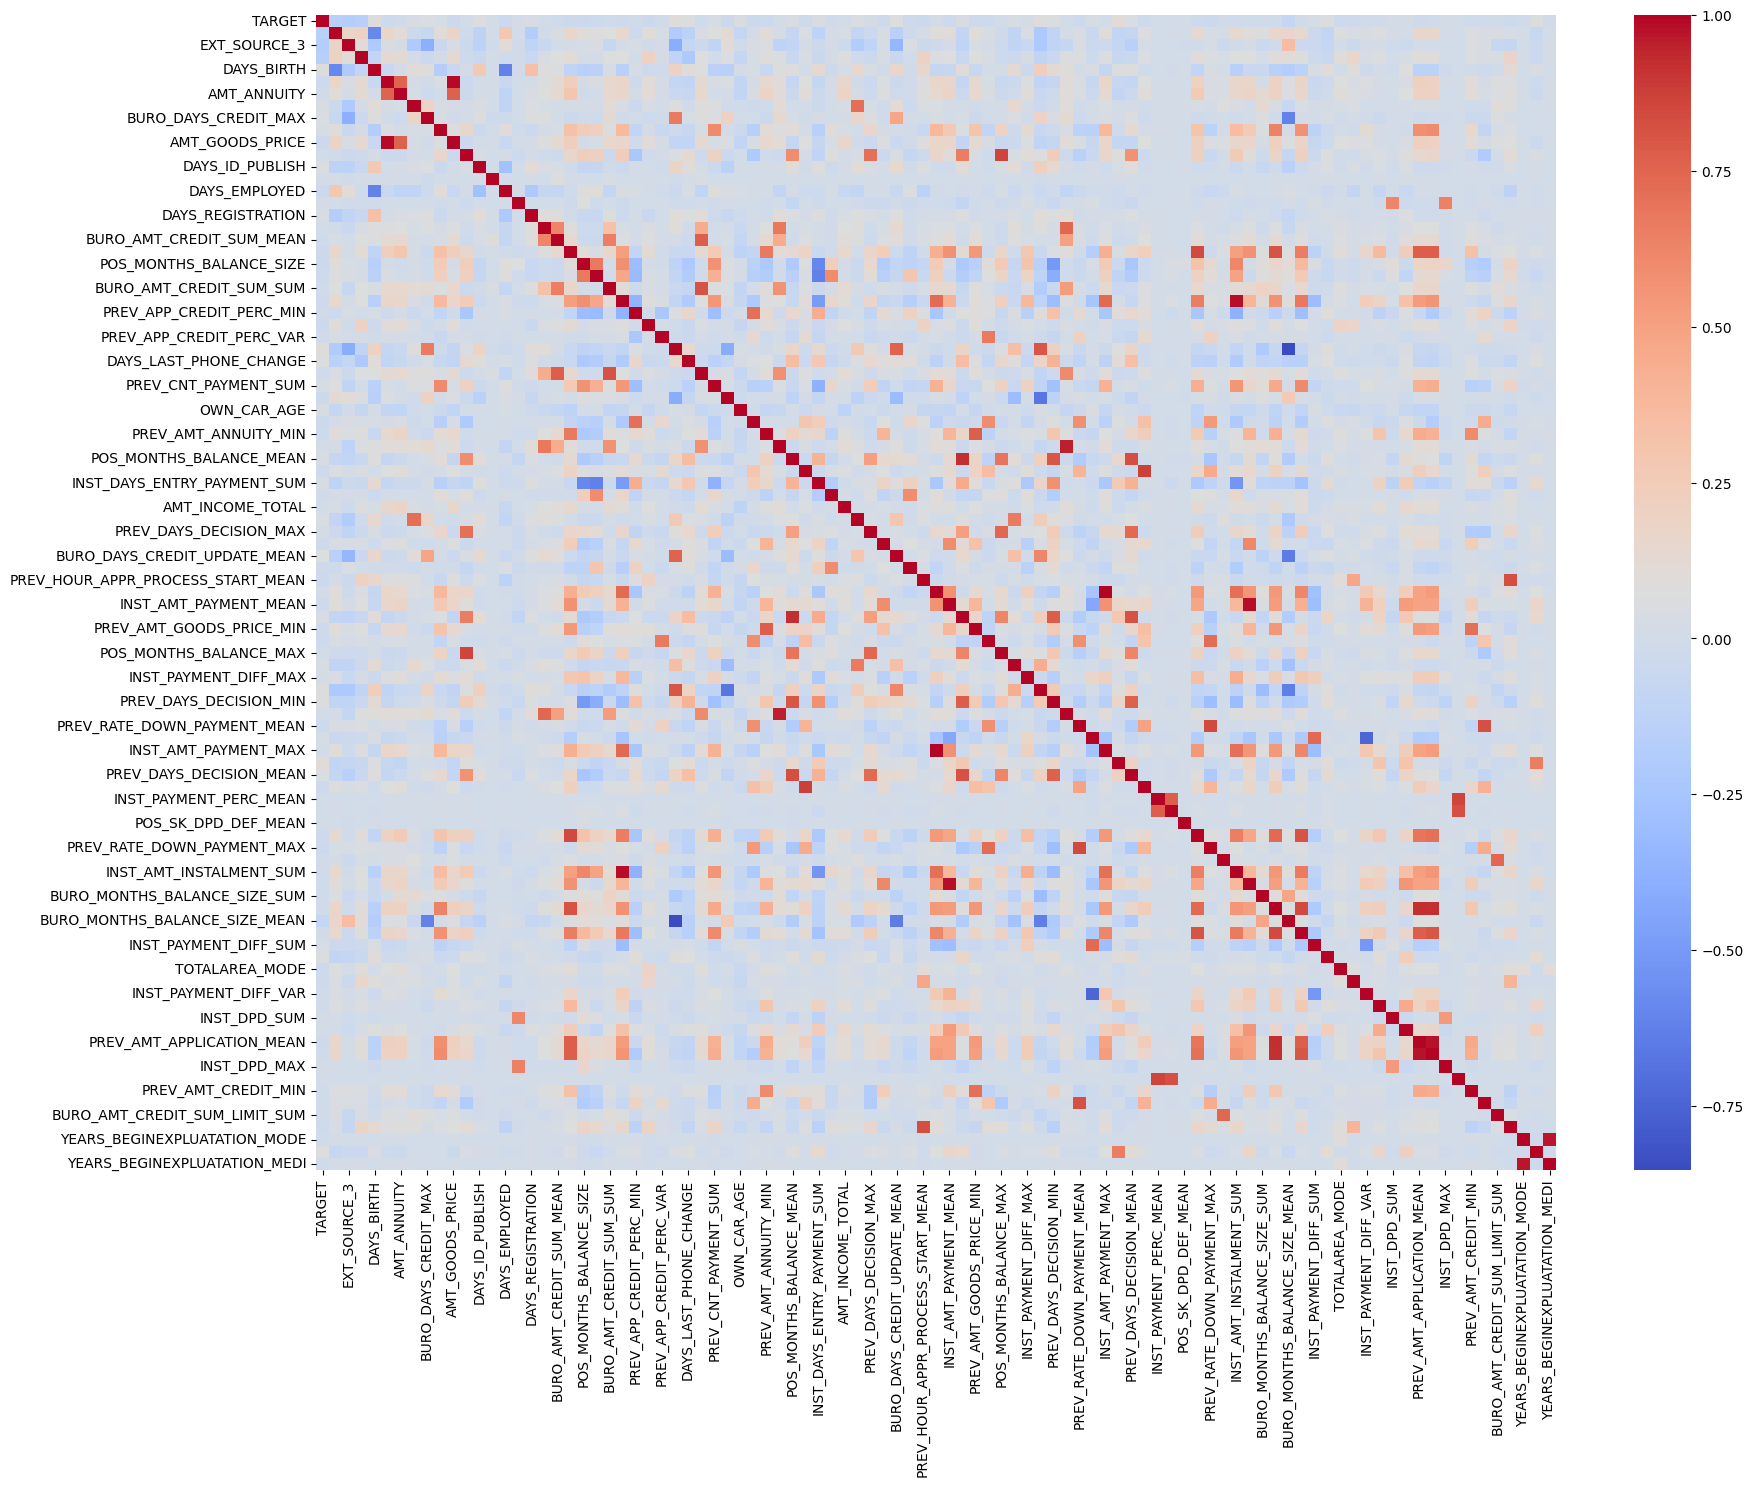

In [ ]:
num_cols = df_top100.select_dtypes(include=np.number).columns.tolist()
cat_cols = df_top100.select_dtypes(include='object').columns.tolist()
# Plot correlation matrix
corr = df_top100[num_cols].corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr, cmap='coolwarm')
plt.show()

In [ ]:
# Lấy upper triangle (phần trên đường chéo) để tránh lặp
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)


In [ ]:
# Ngưỡng tương quan cao
threshold = 0.8

# Tìm các cột có tương quan > threshold
to_drop = [
    column for column in upper.columns
    if any(upper[column] > threshold)
]

print("Các cột sẽ bị loại bỏ do tương quan cao:", to_drop)


Các cột sẽ bị loại bỏ do tương quan cao: ['AMT_GOODS_PRICE', 'BURO_AMT_CREDIT_SUM_MAX', 'INST_DAYS_ENTRY_PAYMENT_MEAN', 'POS_MONTHS_BALANCE_MAX', 'BURO_DAYS_CREDIT_MIN', 'BURO_AMT_CREDIT_SUM_DEBT_MAX', 'INST_AMT_PAYMENT_MAX', 'PREV_DAYS_DECISION_MEAN', 'PREV_AMT_DOWN_PAYMENT_MEAN', 'PREV_AMT_ANNUITY_MAX', 'PREV_RATE_DOWN_PAYMENT_MAX', 'INST_AMT_INSTALMENT_SUM', 'INST_AMT_INSTALMENT_MEAN', 'PREV_AMT_GOODS_PRICE_MEAN', 'PREV_AMT_CREDIT_MAX', 'PREV_AMT_APPLICATION_MEAN', 'PREV_AMT_CREDIT_MEAN', 'INST_PAYMENT_PERC_VAR', 'PREV_RATE_DOWN_PAYMENT_MIN', 'PREV_HOUR_APPR_PROCESS_START_MAX', 'YEARS_BEGINEXPLUATATION_MEDI']


In [ ]:
features_to_keep = ['AMT_GOODS_PRICE']  # danh sách các cột bạn muốn giữ
to_drop_filtered = [col for col in to_drop if col not in features_to_keep]
df_reduced = df_top100.drop(columns=to_drop_filtered)

In [ ]:
df_reduced.columns.values

array(['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_3', 'EXT_SOURCE_2',
       'DAYS_BIRTH', 'AMT_CREDIT', 'AMT_ANNUITY',
       'BURO_DAYS_CREDIT_ENDDATE_MAX', 'BURO_DAYS_CREDIT_MAX',
       'PREV_CNT_PAYMENT_MEAN', 'AMT_GOODS_PRICE',
       'INST_DAYS_ENTRY_PAYMENT_MAX', 'DAYS_ID_PUBLISH',
       'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN', 'DAYS_EMPLOYED',
       'INST_DPD_MEAN', 'DAYS_REGISTRATION',
       'BURO_AMT_CREDIT_SUM_DEBT_MEAN', 'BURO_AMT_CREDIT_SUM_MEAN',
       'PREV_AMT_ANNUITY_MEAN', 'POS_MONTHS_BALANCE_SIZE', 'INST_DBD_SUM',
       'BURO_AMT_CREDIT_SUM_SUM', 'INST_AMT_PAYMENT_SUM',
       'PREV_APP_CREDIT_PERC_MIN', 'REGION_POPULATION_RELATIVE',
       'PREV_APP_CREDIT_PERC_VAR', 'BURO_DAYS_CREDIT_MEAN',
       'DAYS_LAST_PHONE_CHANGE', 'PREV_CNT_PAYMENT_SUM',
       'BURO_DAYS_CREDIT_VAR', 'OWN_CAR_AGE', 'PREV_APP_CREDIT_PERC_MEAN',
       'PREV_AMT_ANNUITY_MIN', 'BURO_AMT_CREDIT_SUM_DEBT_SUM',
       'ORGANIZATION_TYPE', 'POS_MONTHS_BALANCE_MEAN',
       'PREV_AMT_DOWN_PAYMENT_MAX

### Lọc feature dựa trên sự ảnh hưởng đến khả năng trả nơ( nghiệp vụ cho vay)

In [ ]:
ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

# Tạo cột EXT_SOURCE_MEAN trước khi lọc
df['EXT_SOURCE_MEAN'] = df[ext_cols].mean(axis=1, skipna=True)

# Sau đó mới chọn các cột đã lọc
selected_cols = [
    'TARGET', 'EXT_SOURCE_MEAN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'BURO_AMT_CREDIT_SUM_DEBT_MEAN', 'BURO_DAYS_CREDIT_MEAN', 'BURO_DAYS_CREDIT_ENDDATE_MEAN',
    'BURO_AMT_CREDIT_SUM_MEAN','BURO_AMT_CREDIT_MAX_OVERDUE_MEAN', 'BURO_DAYS_CREDIT_UPDATE_MEAN',
    'PREV_AMT_ANNUITY_MEAN', 'PREV_CNT_PAYMENT_SUM','PREV_APP_CREDIT_PERC_MIN', 'PREV_DAYS_DECISION_MAX',
    'INST_DPD_MEAN','INST_PAYMENT_DIFF_MEAN', 'INST_AMT_PAYMENT_MEAN', 'INST_DAYS_ENTRY_PAYMENT_MAX', 'INST_AMT_INSTALMENT_MAX',
    'CC_CNT_DRAWINGS_ATM_CURRENT_MEAN','POS_MONTHS_BALANCE_SIZE',
    'DAYS_BIRTH','DAYS_EMPLOYED', 'OWN_CAR_AGE', 'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS', 'DAYS_ID_PUBLISH', 'DAYS_REGISTRATION', 'DAYS_LAST_PHONE_CHANGE']
# Cuối cùng tạo df_reduced
df_reduced = df[selected_cols].copy()


In [ ]:
df_reduced.head()

,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_DAYS_CREDIT_MEAN,BURO_DAYS_CREDIT_ENDDATE_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,...,CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,POS_MONTHS_BALANCE_SIZE,DAYS_BIRTH,DAYS_EMPLOYED,OWN_CAR_AGE,ORGANIZATION_TYPE,NAME_FAMILY_STATUS,DAYS_ID_PUBLISH,DAYS_REGISTRATION,DAYS_LAST_PHONE_CHANGE
0,1.0,0.161743,202500.0,406597.5,24700.5,49156.199219,-874.00,-349.0,108131.945312,1681.028931,...,NaN,19.0,-9461,-637,NaN,Business Entity Type 3,Single / not married,-2120,-3648.0,-1134.0
1,0.0,0.466797,270000.0,1293502.5,35698.5,0.000000,-1400.75,-544.5,254350.125000,0.000000,...,NaN,28.0,-16765,-1188,NaN,School,Married,-291,-1186.0,-828.0
2,0.0,0.642578,67500.0,135000.0,6750.0,0.000000,-867.00,-488.5,94518.898438,0.000000,...,NaN,4.0,-19046,-225,26.0,Government,Single / not married,-2531,-4260.0,-815.0
3,0.0,0.650391,135000.0,312682.5,29686.5,NaN,NaN,NaN,NaN,NaN,...,NaN,21.0,-19005,-3039,NaN,Business Entity Type 3,Civil marriage,-2437,-9832.0,-617.0
4,0.0,0.322754,121500.0,513000.0,21865.5,0.000000,-1149.00,-783.0,146250.000000,0.000000,...,NaN,66.0,-19932,-3038,NaN,Religion,Single / not married,-3458,-4312.0,-1106.0


### Detect outlier

In [ ]:
Q1 = df_reduced[numeric_cols].quantile(0.25)
Q3 = df_reduced[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

# Điều kiện outlier là < Q1 - 1.5*IQR hoặc > Q3 + 1.5*IQR
is_outlier = ((df_reduced[numeric_cols] < (Q1 - 1.5 * IQR)) |
              (df_reduced[numeric_cols] > (Q3 + 1.5 * IQR)))

# Đếm số outlier mỗi cột
iqr_outlier_counts = is_outlier.sum().sort_values(ascending=False)
print(iqr_outlier_counts[iqr_outlier_counts > 0])


PREV_DAYS_DECISION_MAX          27424
TARGET                          23845
POS_MONTHS_BALANCE_SIZE         16768
BURO_DAYS_CREDIT_UPDATE_MEAN     6468
BURO_DAYS_CREDIT_MEAN            4052
dtype: int64


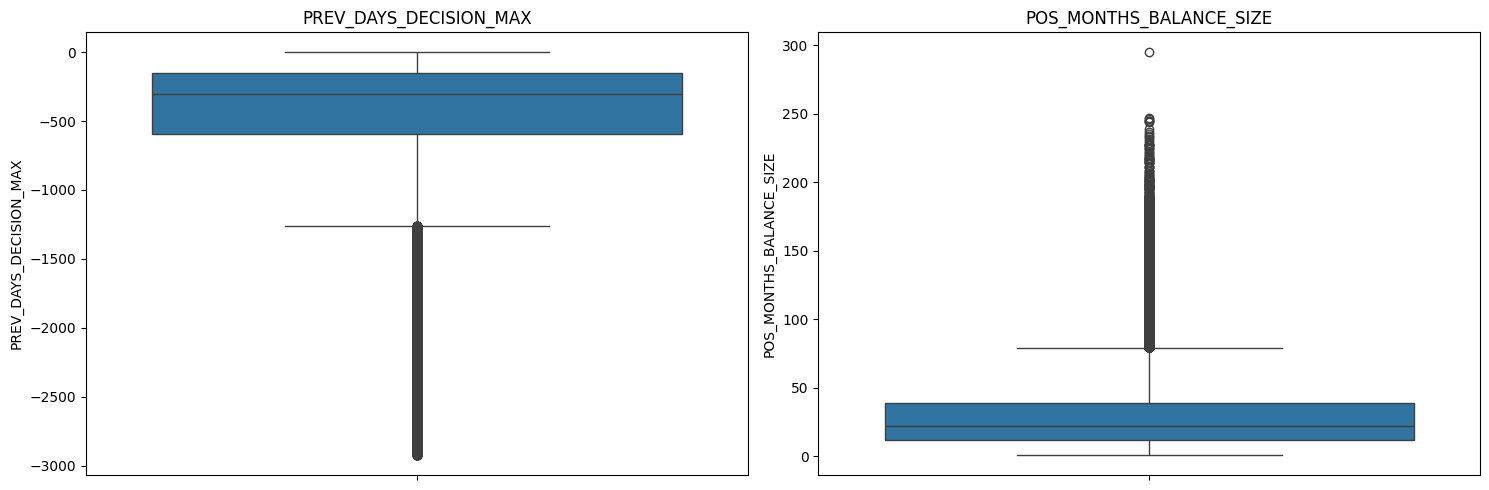

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ví dụ vẽ cho một vài cột
cols_to_plot = ['PREV_DAYS_DECISION_MAX', 'POS_MONTHS_BALANCE_SIZE']
plt.figure(figsize=(15, 5))
for i, col in enumerate(cols_to_plot):
    plt.subplot(1, len(cols_to_plot), i + 1)
    sns.boxplot(y=df_reduced[col])
    plt.title(col)
plt.tight_layout()
plt.show()


### Xử lý mising value

In [ ]:
# Kiểm tra missing values
missing_report =df_reduced.isnull().sum().to_frame(name='Missing Count')
missing_report['Missing Ratio (%)'] = 100 * missing_report['Missing Count'] / len(df_reduced)
missing_report = missing_report.sort_values(by='Missing Ratio (%)', ascending=False)

print(missing_report)

                                  Missing Count  Missing Ratio (%)
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN         267426          78.920016
OWN_CAR_AGE                              224224          66.170686
BURO_AMT_CREDIT_MAX_OVERDUE_MEAN         134730          39.760135
BURO_AMT_CREDIT_SUM_DEBT_MEAN             55487          16.374754
BURO_DAYS_CREDIT_ENDDATE_MEAN             50170          14.805655
TARGET                                    47800          14.106245
BURO_AMT_CREDIT_SUM_MEAN                  47768          14.096802
BURO_DAYS_CREDIT_MEAN                     47766          14.096212
BURO_DAYS_CREDIT_UPDATE_MEAN              47766          14.096212
POS_MONTHS_BALANCE_SIZE                    3005           0.886805
INST_PAYMENT_DIFF_MEAN                     1070           0.315767
INST_DAYS_ENTRY_PAYMENT_MAX                1070           0.315767
INST_AMT_PAYMENT_MEAN                      1070           0.315767
INST_DPD_MEAN                              1070           0.31

In [ ]:
# Xóa các cột có tỷ lệ thiếu > 50%
null_percent = df_reduced.isnull().mean() * 100
high_null_cols = null_percent[null_percent > 50].index.tolist()

df_reduced.drop(columns=high_null_cols, inplace=True)
print(f"Đã xoá {len(high_null_cols)} cột có null > 50%")


Đã xoá 2 cột có null > 50%


In [ ]:
# Các cột điền bằng median
median_cols = [
    'BURO_DAYS_CREDIT_ENDDATE_MEAN', 'BURO_AMT_CREDIT_SUM_MEAN',
    'BURO_DAYS_CREDIT_MEAN', 'BURO_DAYS_CREDIT_UPDATE_MEAN',
    'PREV_AMT_ANNUITY_MEAN', 'PREV_APP_CREDIT_PERC_MIN',
    'EXT_SOURCE_MEAN', 'AMT_ANNUITY', 'POS_MONTHS_BALANCE_SIZE',
    'INST_DPD_MEAN', 'INST_PAYMENT_DIFF_MEAN', 'INST_AMT_PAYMENT_MEAN',
    'INST_AMT_INSTALMENT_MAX', 'INST_DAYS_ENTRY_PAYMENT_MAX',
    'PREV_DAYS_DECISION_MAX', 'PREV_CNT_PAYMENT_SUM'
]

for col in median_cols:
    df_reduced[col] = df_reduced[col].fillna(df_reduced[col].median())

# Đối với BURO_AMT_CREDIT_SUM_DEBT_MEAN: giữ lại và điền median
df_reduced['BURO_AMT_CREDIT_SUM_DEBT_MEAN'] = df_reduced['BURO_AMT_CREDIT_SUM_DEBT_MEAN'].fillna(df_reduced['BURO_AMT_CREDIT_SUM_DEBT_MEAN'].median())

# Đối với BURO_AMT_CREDIT_MAX_OVERDUE_MEAN: cân nhắc loại hoặc điền 0
df_reduced['BURO_AMT_CREDIT_MAX_OVERDUE_MEAN'] = df_reduced['BURO_AMT_CREDIT_MAX_OVERDUE_MEAN'].fillna(0)


In [ ]:
df_reduced.head()

,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_DAYS_CREDIT_MEAN,BURO_DAYS_CREDIT_ENDDATE_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,...,INST_DAYS_ENTRY_PAYMENT_MAX,INST_AMT_INSTALMENT_MAX,POS_MONTHS_BALANCE_SIZE,DAYS_BIRTH,DAYS_EMPLOYED,ORGANIZATION_TYPE,NAME_FAMILY_STATUS,DAYS_ID_PUBLISH,DAYS_REGISTRATION,DAYS_LAST_PHONE_CHANGE
0,1.0,0.161743,202500.0,406597.5,24700.5,49156.199219,-874.00,-349.000000,108131.945312,1681.028931,...,-49.0,53093.746094,19.0,-9461,-637,Business Entity Type 3,Single / not married,-2120,-3648.0,-1134.0
1,0.0,0.466797,270000.0,1293502.5,35698.5,0.000000,-1400.75,-544.500000,254350.125000,0.000000,...,-544.0,560835.375000,28.0,-16765,-1188,School,Married,-291,-1186.0,-828.0
2,0.0,0.642578,67500.0,135000.0,6750.0,0.000000,-867.00,-488.500000,94518.898438,0.000000,...,-727.0,10573.964844,4.0,-19046,-225,Government,Single / not married,-2531,-4260.0,-815.0
3,0.0,0.650391,135000.0,312682.5,29686.5,44971.601562,-1053.25,-138.636368,194400.000000,0.000000,...,-12.0,691786.875000,21.0,-19005,-3039,Business Entity Type 3,Civil marriage,-2437,-9832.0,-617.0
4,0.0,0.322754,121500.0,513000.0,21865.5,0.000000,-1149.00,-783.000000,146250.000000,0.000000,...,-14.0,22678.785156,66.0,-19932,-3038,Religion,Single / not married,-3458,-4312.0,-1106.0


In [ ]:
df_reduced.columns.values

array(['TARGET', 'EXT_SOURCE_MEAN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
       'AMT_ANNUITY', 'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
       'BURO_DAYS_CREDIT_MEAN', 'BURO_DAYS_CREDIT_ENDDATE_MEAN',
       'BURO_AMT_CREDIT_SUM_MEAN', 'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
       'BURO_DAYS_CREDIT_UPDATE_MEAN', 'PREV_AMT_ANNUITY_MEAN',
       'PREV_CNT_PAYMENT_SUM', 'PREV_APP_CREDIT_PERC_MIN',
       'PREV_DAYS_DECISION_MAX', 'INST_DPD_MEAN',
       'INST_PAYMENT_DIFF_MEAN', 'INST_AMT_PAYMENT_MEAN',
       'INST_DAYS_ENTRY_PAYMENT_MAX', 'INST_AMT_INSTALMENT_MAX',
       'POS_MONTHS_BALANCE_SIZE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
       'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS', 'DAYS_ID_PUBLISH',
       'DAYS_REGISTRATION', 'DAYS_LAST_PHONE_CHANGE'], dtype=object)

### Save df_reduced

In [ ]:
# Xuất file CSV
df_reduced.to_csv(dataPath+"df_reduced.csv", index=False)


### Dictionary

| Tên biến                           | Mô tả                                                                           |
| ---------------------------------- | ------------------------------------------------------------------------------- |
| `TARGET`                           | Biến mục tiêu: 1 nếu khách hàng vỡ nợ, 0 nếu khách hàng trả đúng hạn            |
| `EXT_SOURCE_MEAN`                  | Trung bình điểm tín dụng từ 3 nguồn bên ngoài (EXT\_SOURCE\_1, 2, 3)            |
| `AMT_INCOME_TOTAL`                 | Tổng thu nhập hàng năm của khách hàng                                           |
| `AMT_CREDIT`                       | Tổng số tiền khoản vay khách hàng đã được cấp                                   |
| `AMT_ANNUITY`                      | Số tiền khách hàng phải trả mỗi kỳ (trả góp định kỳ)                            |
| `BURO_AMT_CREDIT_SUM_DEBT_MEAN`    | Trung bình tổng nợ còn lại từ các khoản vay cũ (bảng bureau)                    |
| `BURO_DAYS_CREDIT_MEAN`            | Trung bình số ngày kể từ khi mở các khoản vay trước (âm)                        |
| `BURO_DAYS_CREDIT_ENDDATE_MEAN`    | Trung bình số ngày đến hạn trả của khoản vay (âm nếu đã kết thúc)               |
| `BURO_AMT_CREDIT_SUM_MEAN`         | Trung bình tổng số tiền vay từ các khoản cũ                                     |
| `BURO_AMT_CREDIT_MAX_OVERDUE_MEAN` | Trung bình khoản nợ quá hạn lớn nhất trong lịch sử vay                          |
| `BURO_DAYS_CREDIT_UPDATE_MEAN`     | Trung bình số ngày kể từ lần cập nhật gần nhất từ bureau                        |
| `PREV_AMT_ANNUITY_MEAN`            | Trung bình số tiền phải trả mỗi kỳ từ các đơn vay trước                         |
| `PREV_CNT_PAYMENT_SUM`             | Tổng số kỳ thanh toán trong các đơn vay trước                                   |
| `PREV_APP_CREDIT_PERC_MIN`         | Tỷ lệ nhỏ nhất giữa khoản vay được duyệt và khoản vay yêu cầu                   |
| `PREV_DAYS_DECISION_MAX`           | Ngày phê duyệt gần nhất của các đơn vay trước                                   |
| `INST_DPD_MEAN`                    | Trung bình số ngày quá hạn thanh toán trong lịch sử trả góp                     |
| `INST_PAYMENT_DIFF_MEAN`           | Trung bình chênh lệch giữa số tiền phải trả và số tiền thực trả                 |
| `INST_AMT_PAYMENT_MEAN`            | Trung bình số tiền khách hàng thực sự đã thanh toán                             |
| `INST_DAYS_ENTRY_PAYMENT_MAX`      | Ngày ghi nhận thanh toán xa nhất trong dữ liệu trả góp                          |
| `INST_AMT_INSTALMENT_MAX`          | Khoản trả góp lớn nhất phải trả trong lịch sử                                   |
| `POS_MONTHS_BALANCE_SIZE`          | Số lượng tháng có thông tin POS hoặc Cash loan                                  |
| `DAYS_BIRTH`                       | Số ngày từ ngày sinh đến thời điểm đăng ký (âm, tuổi càng cao giá trị càng nhỏ) |
| `DAYS_EMPLOYED`                    | Số ngày khách hàng đã làm việc (âm)                                             |
| `ORGANIZATION_TYPE`                | Loại tổ chức/doanh nghiệp nơi khách hàng làm việc                               |
| `NAME_FAMILY_STATUS`               | Tình trạng hôn nhân của khách hàng                                              |
| `DAYS_ID_PUBLISH`                  | Số ngày kể từ khi cấp lại/chỉnh sửa giấy tờ tùy thân                            |
| `DAYS_REGISTRATION`                | Số ngày kể từ khi khách hàng đăng ký nơi cư trú                                 |
| `DAYS_LAST_PHONE_CHANGE`           | Số ngày kể từ lần thay đổi số điện thoại cuối cùng                              |


# Phân tích riêng từng bảng

In [ ]:
application = FE_application_data(application_train)
print(application.shape)

/tmp/ipykernel_3397587/2814060943.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['CREDIT_INCOME_PERCENT'] = data['AMT_CREDIT'] / data['AMT_INCOME_TOTAL']
/tmp/ipykernel_3397587/2814060943.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['ANNUITY_INCOME_PERCENT'] = data['AMT_ANNUITY'] / data['AMT_INCOME_TOTAL']
/tmp/ipykernel_3397587/2814060943.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining 

(307511, 129)


## Bureau

In [ ]:
# Bật/tắt chế độ debug
debug = False
num_rows = 10000 if debug else None

# Load dữ liệu chính (new customers)
df_no_prev = app_no_prev.copy()

# Bureau + bureau_balance
bureau_agg = bureau_and_balance(bureau_data, bureau_balance, num_rows)
print("Bureau df shape:", bureau_agg.shape)
df_no_prev = df_no_prev.join(bureau_agg, how='left', on='SK_ID_CURR')
# In kích thước tổng thể của dataframe cuối cùng
print("Final dataframe shape:", df_no_prev.shape)

Bureau df shape: (305811, 27)
Final dataframe shape: (17398, 149)


In [ ]:
def generate_credit_type_code(x):
    if x == 'Closed':
        y = 0
    elif x=='Active':
        y = 1
    else:
        y = 2
    return y


def FE_bureau_data_1(bureau_data):

    bureau_data['CREDIT_DURATION'] = -bureau_data['DAYS_CREDIT'] + bureau_data['DAYS_CREDIT_ENDDATE']
    bureau_data['ENDDATE_DIFF'] = bureau_data['DAYS_CREDIT_ENDDATE'] - bureau_data['DAYS_ENDDATE_FACT']
    bureau_data['UPDATE_DIFF'] = bureau_data['DAYS_CREDIT_ENDDATE'] - bureau_data['DAYS_CREDIT_UPDATE']
    bureau_data['DEBT_PERCENTAGE'] = bureau_data['AMT_CREDIT_SUM'] / bureau_data['AMT_CREDIT_SUM_DEBT']
    bureau_data['DEBT_CREDIT_DIFF'] = bureau_data['AMT_CREDIT_SUM'] - bureau_data['AMT_CREDIT_SUM_DEBT']
    bureau_data['CREDIT_TO_ANNUITY_RATIO'] = bureau_data['AMT_CREDIT_SUM'] / bureau_data['AMT_ANNUITY']
    bureau_data['DEBT_TO_ANNUITY_RATIO'] = bureau_data['AMT_CREDIT_SUM_DEBT'] / bureau_data['AMT_ANNUITY']
    bureau_data['CREDIT_OVERDUE_DIFF'] = bureau_data['AMT_CREDIT_SUM'] - bureau_data['AMT_CREDIT_SUM_OVERDUE']

    #Refer :- https://www.kaggle.com/c/home-credit-default-risk/discussion/57750
    #Calculating the Number of Past Loans for each Customer
    no_loans_per_customer = bureau_data[['SK_ID_CURR', 'SK_ID_BUREAU']].groupby(by = \
                                                                    ['SK_ID_CURR'])['SK_ID_BUREAU'].count()
    no_loans_per_customer = no_loans_per_customer.reset_index().rename(columns={'SK_ID_BUREAU': 'CUSTOMER_LOAN_COUNT'})
    bureau_data = bureau_data.merge(no_loans_per_customer, on='SK_ID_CURR', how='left')

    #Calculating the Past Credit Types per Customer
    credit_types_per_customer = bureau_data[['SK_ID_CURR','CREDIT_TYPE']].groupby(by=['SK_ID_CURR'])['CREDIT_TYPE'].nunique()
    credit_types_per_customer = credit_types_per_customer.reset_index().rename(columns={'CREDIT_TYPE':'CUSTOMER_CREDIT_TYPES'})
    bureau_data = bureau_data.merge(credit_types_per_customer, on='SK_ID_CURR',how='left')

    #Average Loan Type per Customer
    bureau_data['AVG_LOAN_TYPE'] = bureau_data['CUSTOMER_LOAN_COUNT']/bureau_data['CUSTOMER_CREDIT_TYPES']

    bureau_data['CREDIT_TYPE_CODE'] = bureau_data.apply(lambda x:\
                                        generate_credit_type_code(x.CREDIT_ACTIVE), axis=1)

    customer_credit_code_mean = bureau_data[['SK_ID_CURR','CREDIT_TYPE_CODE']].groupby(by=['SK_ID_CURR'])['CREDIT_TYPE_CODE'].mean()
    customer_credit_code_mean.reset_index().rename(columns={'CREDIT_TYPE_CODE':'CUSTOMER_CREDIT_CODE_MEAN'})
    bureau_data = bureau_data.merge(customer_credit_code_mean, on='SK_ID_CURR', how='left')

    #Computing the Ratio of Total Customer Credit and the Total Customer Debt
    bureau_data['AMT_CREDIT_SUM'] = bureau_data['AMT_CREDIT_SUM'].fillna(0)
    bureau_data['AMT_CREDIT_SUM_DEBT'] = bureau_data['AMT_CREDIT_SUM_DEBT'].fillna(0)
    bureau_data['AMT_ANNUITY'] = bureau_data['AMT_ANNUITY'].fillna(0)

    credit_sum_customer = bureau_data[['SK_ID_CURR','AMT_CREDIT_SUM']].groupby(by=\
                                                                            ['SK_ID_CURR'])['AMT_CREDIT_SUM'].sum()
    credit_sum_customer = credit_sum_customer.reset_index().rename(columns={'AMT_CREDIT_SUM':'TOTAL_CREDIT_SUM'})
    bureau_data = bureau_data.merge(credit_sum_customer, on='SK_ID_CURR', how='left')

    credit_debt_sum_customer = bureau_data[['SK_ID_CURR','AMT_CREDIT_SUM_DEBT']].groupby(by=\
                                                                        ['SK_ID_CURR'])['AMT_CREDIT_SUM_DEBT'].sum()
    credit_debt_sum_customer = credit_debt_sum_customer.reset_index().rename(columns={'AMT_CREDIT_SUM_DEBT':'TOTAL_DEBT_SUM'})
    bureau_data = bureau_data.merge(credit_debt_sum_customer, on='SK_ID_CURR', how='left')
    bureau_data['CREDIT_DEBT_RATIO'] = bureau_data['TOTAL_CREDIT_SUM']/bureau_data['TOTAL_DEBT_SUM']

    return bureau_data

In [ ]:
bureau_data_fe = FE_bureau_data_1(bureau_data)

#One Hot Encoding the Bureau Datasets
bureau_data, bureau_data_columns = one_hot_encode(bureau_data_fe)
bureau_balance, bureau_balance_columns = one_hot_encode(bureau_balance)

In [ ]:
def FE_bureau_data_2(bureau_data,bureau_balance,bureau_data_columns,bureau_balance_columns):

    bureau_balance_agg = {'MONTHS_BALANCE': ['mean']}

    for column in bureau_balance_columns:
        bureau_balance_agg[column] = ['min','max','mean','size']
        bureau_balance_final_agg = bureau_balance.groupby('SK_ID_BUREAU').agg(bureau_balance_agg)

    col_list_1 =[]

    for col in bureau_balance_final_agg.columns.tolist():
        col_list_1.append(col[0] + "_" + col[1].upper())

    bureau_balance_final_agg.columns = pd.Index(col_list_1)
    bureau_data_balance = bureau_data.join(bureau_balance_final_agg, how='left', on='SK_ID_BUREAU')
    bureau_data_balance.drop(['SK_ID_BUREAU'], axis=1, inplace= True)

    del bureau_balance_final_agg
    gc.collect()


    numerical_agg = {'AMT_CREDIT_SUM_DEBT': ['mean', 'sum'],'AMT_CREDIT_SUM_OVERDUE': ['mean','sum'],
        'DAYS_CREDIT': ['mean', 'var'],'DAYS_CREDIT_UPDATE': ['mean','min'],'CREDIT_DAY_OVERDUE': ['mean','min'],
        'DAYS_CREDIT_ENDDATE': ['mean'],'CNT_CREDIT_PROLONG': ['sum'],
        'AMT_CREDIT_SUM_LIMIT': ['mean', 'sum'],'AMT_CREDIT_MAX_OVERDUE': ['mean','max'],
        'AMT_ANNUITY': ['max', 'mean','sum'],'AMT_CREDIT_SUM': ['mean', 'sum','max']
      }
    categorical_agg = {}

    for col in bureau_data_columns:
        categorical_agg[col] = ['mean']
        categorical_agg[col] = ['max']

    for col in bureau_balance_columns:
        categorical_agg[col + "_MEAN"] = ['mean']
        categorical_agg[col + "_MIN"] = ['min']
        categorical_agg[col + "_MAX"] = ['max']

    bureau_data_balance_2 = bureau_data_balance.groupby('SK_ID_CURR').agg({**numerical_agg,\
                                                                       **categorical_agg})
    col_list_2=[]

    for col in bureau_data_balance_2.columns.tolist():
        col_list_2.append('BUREAU_'+col[0]+'_'+col[1])
    bureau_data_balance_2.columns = pd.Index(col_list_2)


    bureau_data_balance_3 = bureau_data_balance[bureau_data_balance['CREDIT_ACTIVE_Active'] == 1]
    bureau_data_balance_3_agg = bureau_data_balance_3.groupby('SK_ID_CURR').agg(numerical_agg)

    col_list_3=[]
    for col in bureau_data_balance_3_agg.columns.tolist():
        col_list_3.append('A_'+col[0]+'_'+col[1].upper())

    bureau_data_balance_3_agg.columns = pd.Index(col_list_3)
    b3_final = bureau_data_balance_2.join(bureau_data_balance_3_agg, how='left', \
                                      on='SK_ID_CURR')

    bureau_data_balance_4 = bureau_data_balance[bureau_data_balance['CREDIT_ACTIVE_Closed'] == 1]
    bureau_data_balance_4_agg = bureau_data_balance_4.groupby('SK_ID_CURR').agg(numerical_agg)
    col_list_4 =[]

    for col in bureau_data_balance_4_agg.columns.tolist():
        col_list_4.append('C_'+col[0]+'_'+col[1].upper())

    bureau_data_balance_4_agg.columns = pd.Index(col_list_4)
    bureau_data_balance_final = bureau_data_balance_2.join(bureau_data_balance_4_agg, \
                                                    how='left', on='SK_ID_CURR')

    del bureau_data_balance_3, bureau_data_balance_4_agg
    gc.collect()

    return bureau_data_balance_final

In [ ]:
bureau_data_balance_final = FE_bureau_data_2(bureau_data, bureau_balance,bureau_data_columns,\
                                             bureau_balance_columns)
bureau= df.join(bureau_data_balance_final, how='left', \
                                         on='SK_ID_CURR')

In [ ]:
bureau.shape

(307511, 99)

In [ ]:
# Bar plot number of missing values column ascending
cols_with_null = bureau.isnull().mean()
cols_with_null

SK_ID_CURR                            0.000000
TARGET                                0.000000
BUREAU_AMT_CREDIT_SUM_DEBT_mean       0.143149
BUREAU_AMT_CREDIT_SUM_DEBT_sum        0.143149
BUREAU_AMT_CREDIT_SUM_OVERDUE_mean    0.143149
                                        ...   
C_AMT_ANNUITY_MEAN                    0.251523
C_AMT_ANNUITY_SUM                     0.251523
C_AMT_CREDIT_SUM_MEAN                 0.251523
C_AMT_CREDIT_SUM_SUM                  0.251523
C_AMT_CREDIT_SUM_MAX                  0.251523
Length: 99, dtype: float64

In [ ]:
num_cols = bureau.select_dtypes(include=np.number).columns.tolist()
cat_cols = bureau.select_dtypes(include='object').columns.tolist()

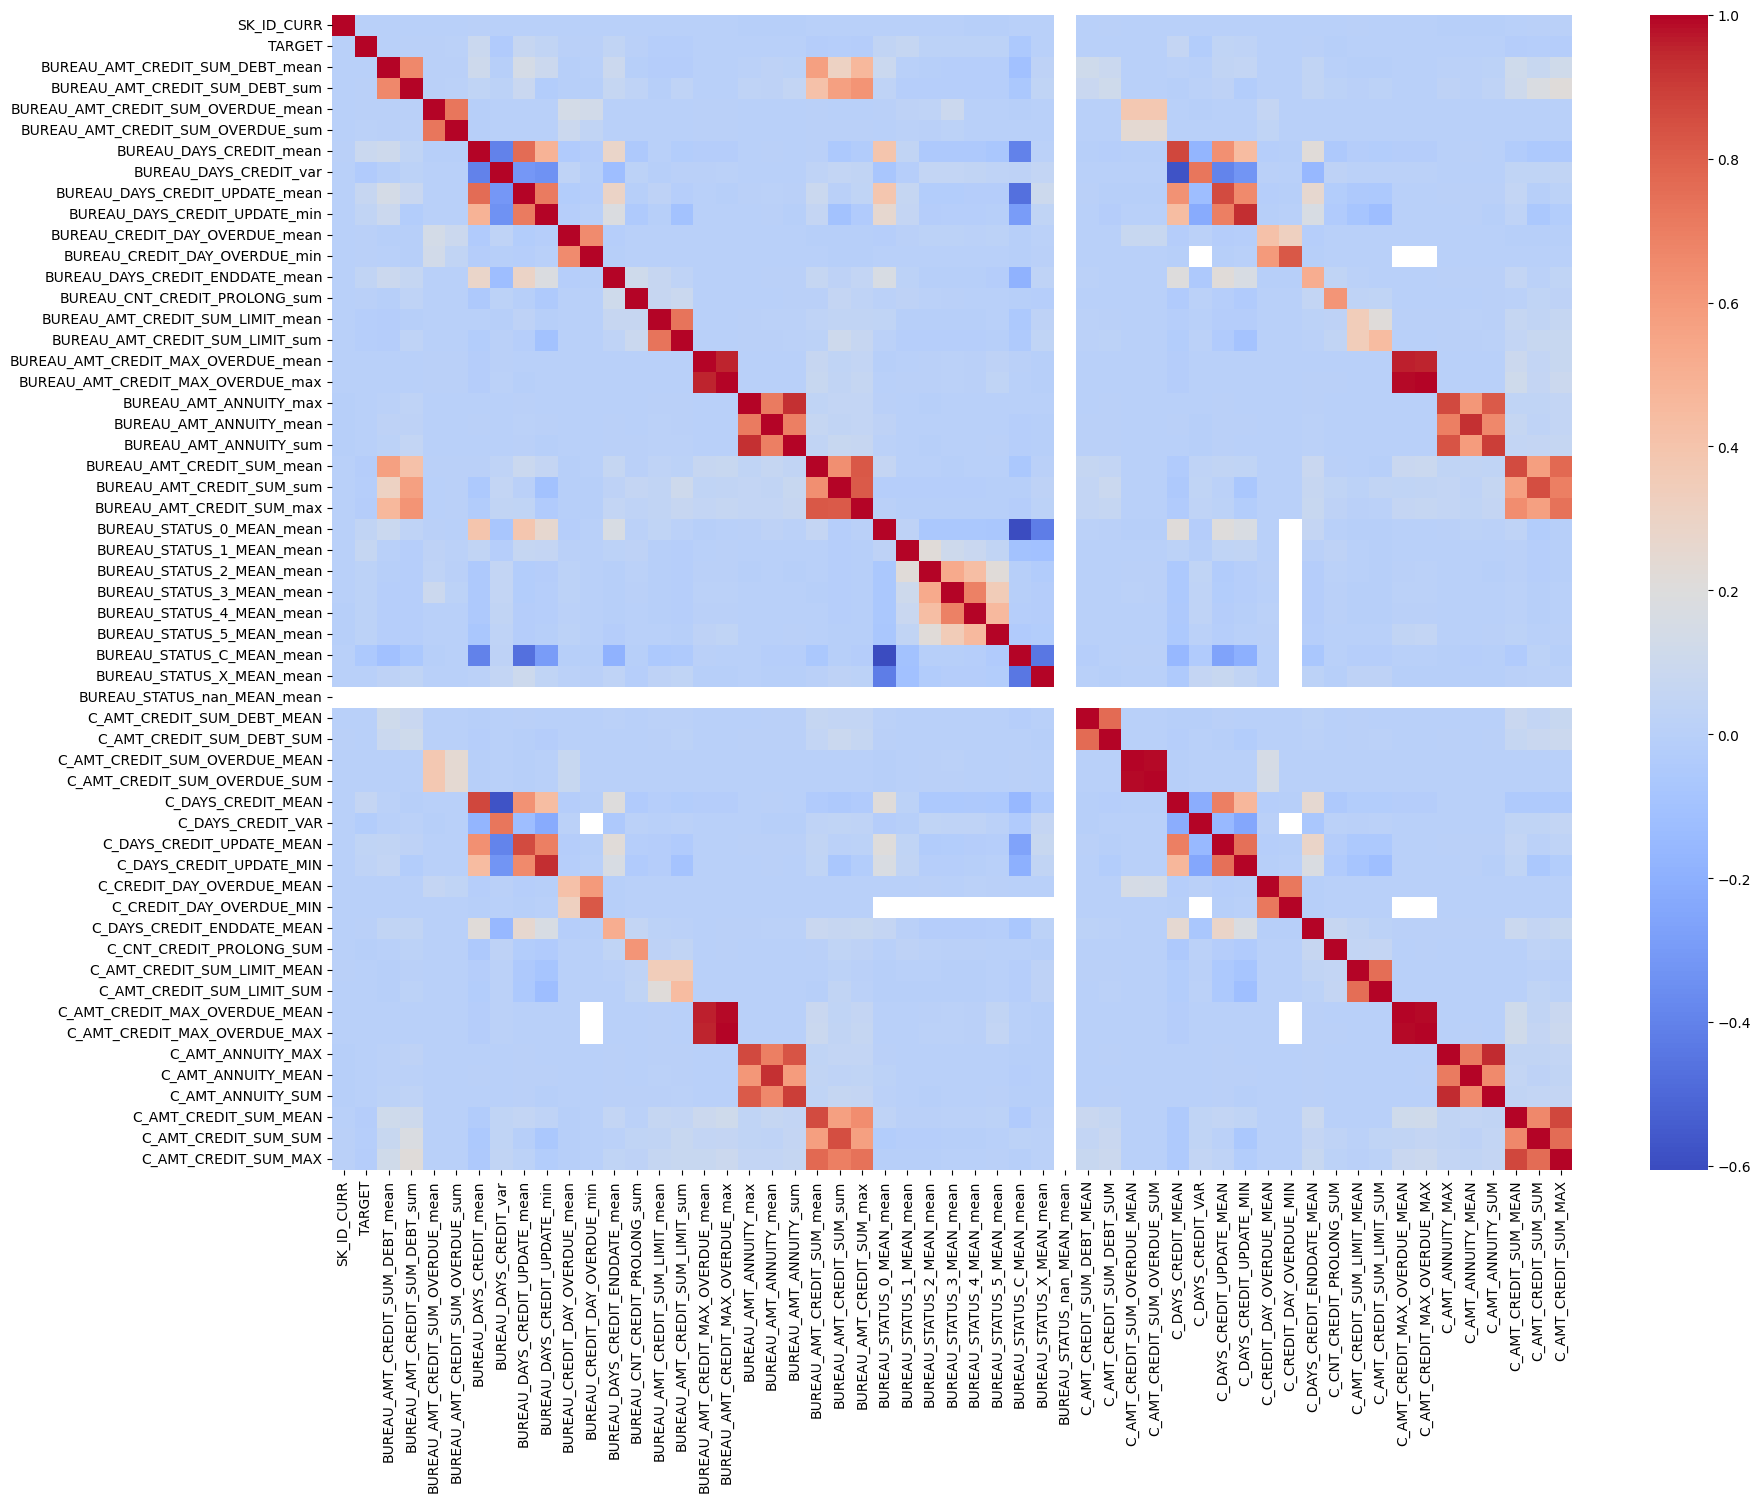

In [ ]:
# Plot correlation matrix
corr = bureau[num_cols].corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr, cmap='coolwarm')
plt.show()

## Previous application

In [ ]:
def FE_previous_application(previous_application):

    prev_app, previous_application_columns = one_hot_encode(previous_application)

    prev_app['APPLICATION_CREDIT_DIFF'] = prev_app['AMT_APPLICATION'] - prev_app['AMT_CREDIT']
    prev_app['APPLICATION_CREDIT_RATIO'] = prev_app['AMT_APPLICATION'] / prev_app['AMT_CREDIT']
    prev_app['CREDIT_TO_ANNUITY_RATIO'] = prev_app['AMT_CREDIT']/prev_app['AMT_ANNUITY']
    prev_app['DOWN_PAYMENT_TO_CREDIT'] = prev_app['AMT_DOWN_PAYMENT'] / prev_app['AMT_CREDIT']

    total_payment = prev_app['AMT_ANNUITY'] * prev_app['CNT_PAYMENT']
    prev_app['SIMPLE_INTERESTS'] = (total_payment/prev_app['AMT_CREDIT'] - 1)/prev_app['CNT_PAYMENT']

    prev_app['DAYS_LAST_DUE_DIFF'] = prev_app['DAYS_LAST_DUE_1ST_VERSION'] - prev_app['DAYS_LAST_DUE']

    numerical_agg_prev = {'AMT_ANNUITY': ['max', 'mean'], 'AMT_APPLICATION': ['max','mean'],\
                     'AMT_CREDIT':['max','mean'], 'AMT_DOWN_PAYMENT': ['max','mean'],\
                      'AMT_GOODS_PRICE':['mean','sum'], 'HOUR_APPR_PROCESS_START' :\
                      ['max','mean'], 'RATE_DOWN_PAYMENT':['max','mean'], 'RATE_INTEREST_PRIMARY':\
                      ['max','mean'],'RATE_INTEREST_PRIVILEGED':['max','mean'], \
                      'DAYS_DECISION': ['max','mean'], 'CNT_PAYMENT' :['mean','sum'], \
                      'DAYS_FIRST_DRAWING': ['max','mean'], 'DAYS_TERMINATION' : ['max','mean'],\
                      'APPLICATION_CREDIT_RATIO': ['max','mean'], 'DOWN_PAYMENT_TO_CREDIT' : \
                      ['max','mean'], 'DAYS_LAST_DUE_DIFF': ['max','mean']}

    categorical_agg_prev = {}

    for column in previous_application_columns:
        categorical_agg_prev[column] = ['mean']

    prev_app_agg1 = prev_app.groupby('SK_ID_CURR').agg({**numerical_agg_prev, \
                                                    **categorical_agg_prev})
    col_list_5 =[]

    for col in prev_app_agg1.columns.tolist():
        col_list_5.append('PREV_'+col[0]+'_'+col[1].upper())

    prev_app_agg1.columns = pd.Index(col_list_5)

    prev_app_cs_approved = prev_app[prev_app['NAME_CONTRACT_STATUS_Approved']==1]
    prev_app_agg2 = prev_app_cs_approved.groupby('SK_ID_CURR').agg(numerical_agg_prev)

    col_list_6 = []

    for col in prev_app_agg2.columns.tolist():
        col_list_6.append('CS_APP_' + col[0] + '_' + col[1].upper())

    prev_app_agg2.columns = pd.Index(col_list_6)

    prev_app_agg1_join = prev_app_agg1.join(prev_app_agg2, how='left', on='SK_ID_CURR')

    prev_app_cs_refused = prev_app[prev_app['NAME_CONTRACT_STATUS_Refused']==1]
    prev_app_agg3 = prev_app_cs_refused.groupby('SK_ID_CURR').agg(numerical_agg_prev)

    col_list_7 =[]

    for col in prev_app_agg3.columns.tolist():
        col_list_7.append('CS_REF_' + col[0] + '_' + col[1].upper())

    prev_app_agg3.columns = pd.Index(col_list_7)
    prev_app_agg_final = prev_app_agg1_join.join(prev_app_agg3,how='left', on='SK_ID_CURR')

    del prev_app_agg1_join, prev_app_agg3, prev_app_cs_refused, prev_app_agg1, prev_app_agg2,\
        prev_app_cs_approved
    gc.collect()
    return prev_app_agg_final

In [ ]:
previous_application = FE_previous_application(reduce_memory_usage(previous_application))
previous_application = df.merge(previous_application, on='SK_ID_CURR', how='left')

Memory usage of dataframe is 309.01 MB
Memory usage after optimization is: 309.01 MB
Decreased by 0.0%


In [ ]:
# Bar plot number of missing values column ascending
cols_with_null = previous_application.isnull().mean()
cols_with_null

SK_ID_CURR                              0.000000
TARGET                                  0.000000
PREV_AMT_ANNUITY_MAX                    0.054863
PREV_AMT_ANNUITY_MEAN                   0.054863
PREV_AMT_APPLICATION_MAX                0.053507
                                          ...   
CS_REF_APPLICATION_CREDIT_RATIO_MEAN    0.689884
CS_REF_DOWN_PAYMENT_TO_CREDIT_MAX       0.853111
CS_REF_DOWN_PAYMENT_TO_CREDIT_MEAN      0.853111
CS_REF_DAYS_LAST_DUE_DIFF_MAX           1.000000
CS_REF_DAYS_LAST_DUE_DIFF_MEAN          1.000000
Length: 257, dtype: float64

In [ ]:
num_cols = previous_application.select_dtypes(include=np.number).columns.tolist()
cat_cols = previous_application.select_dtypes(include='object').columns.tolist()

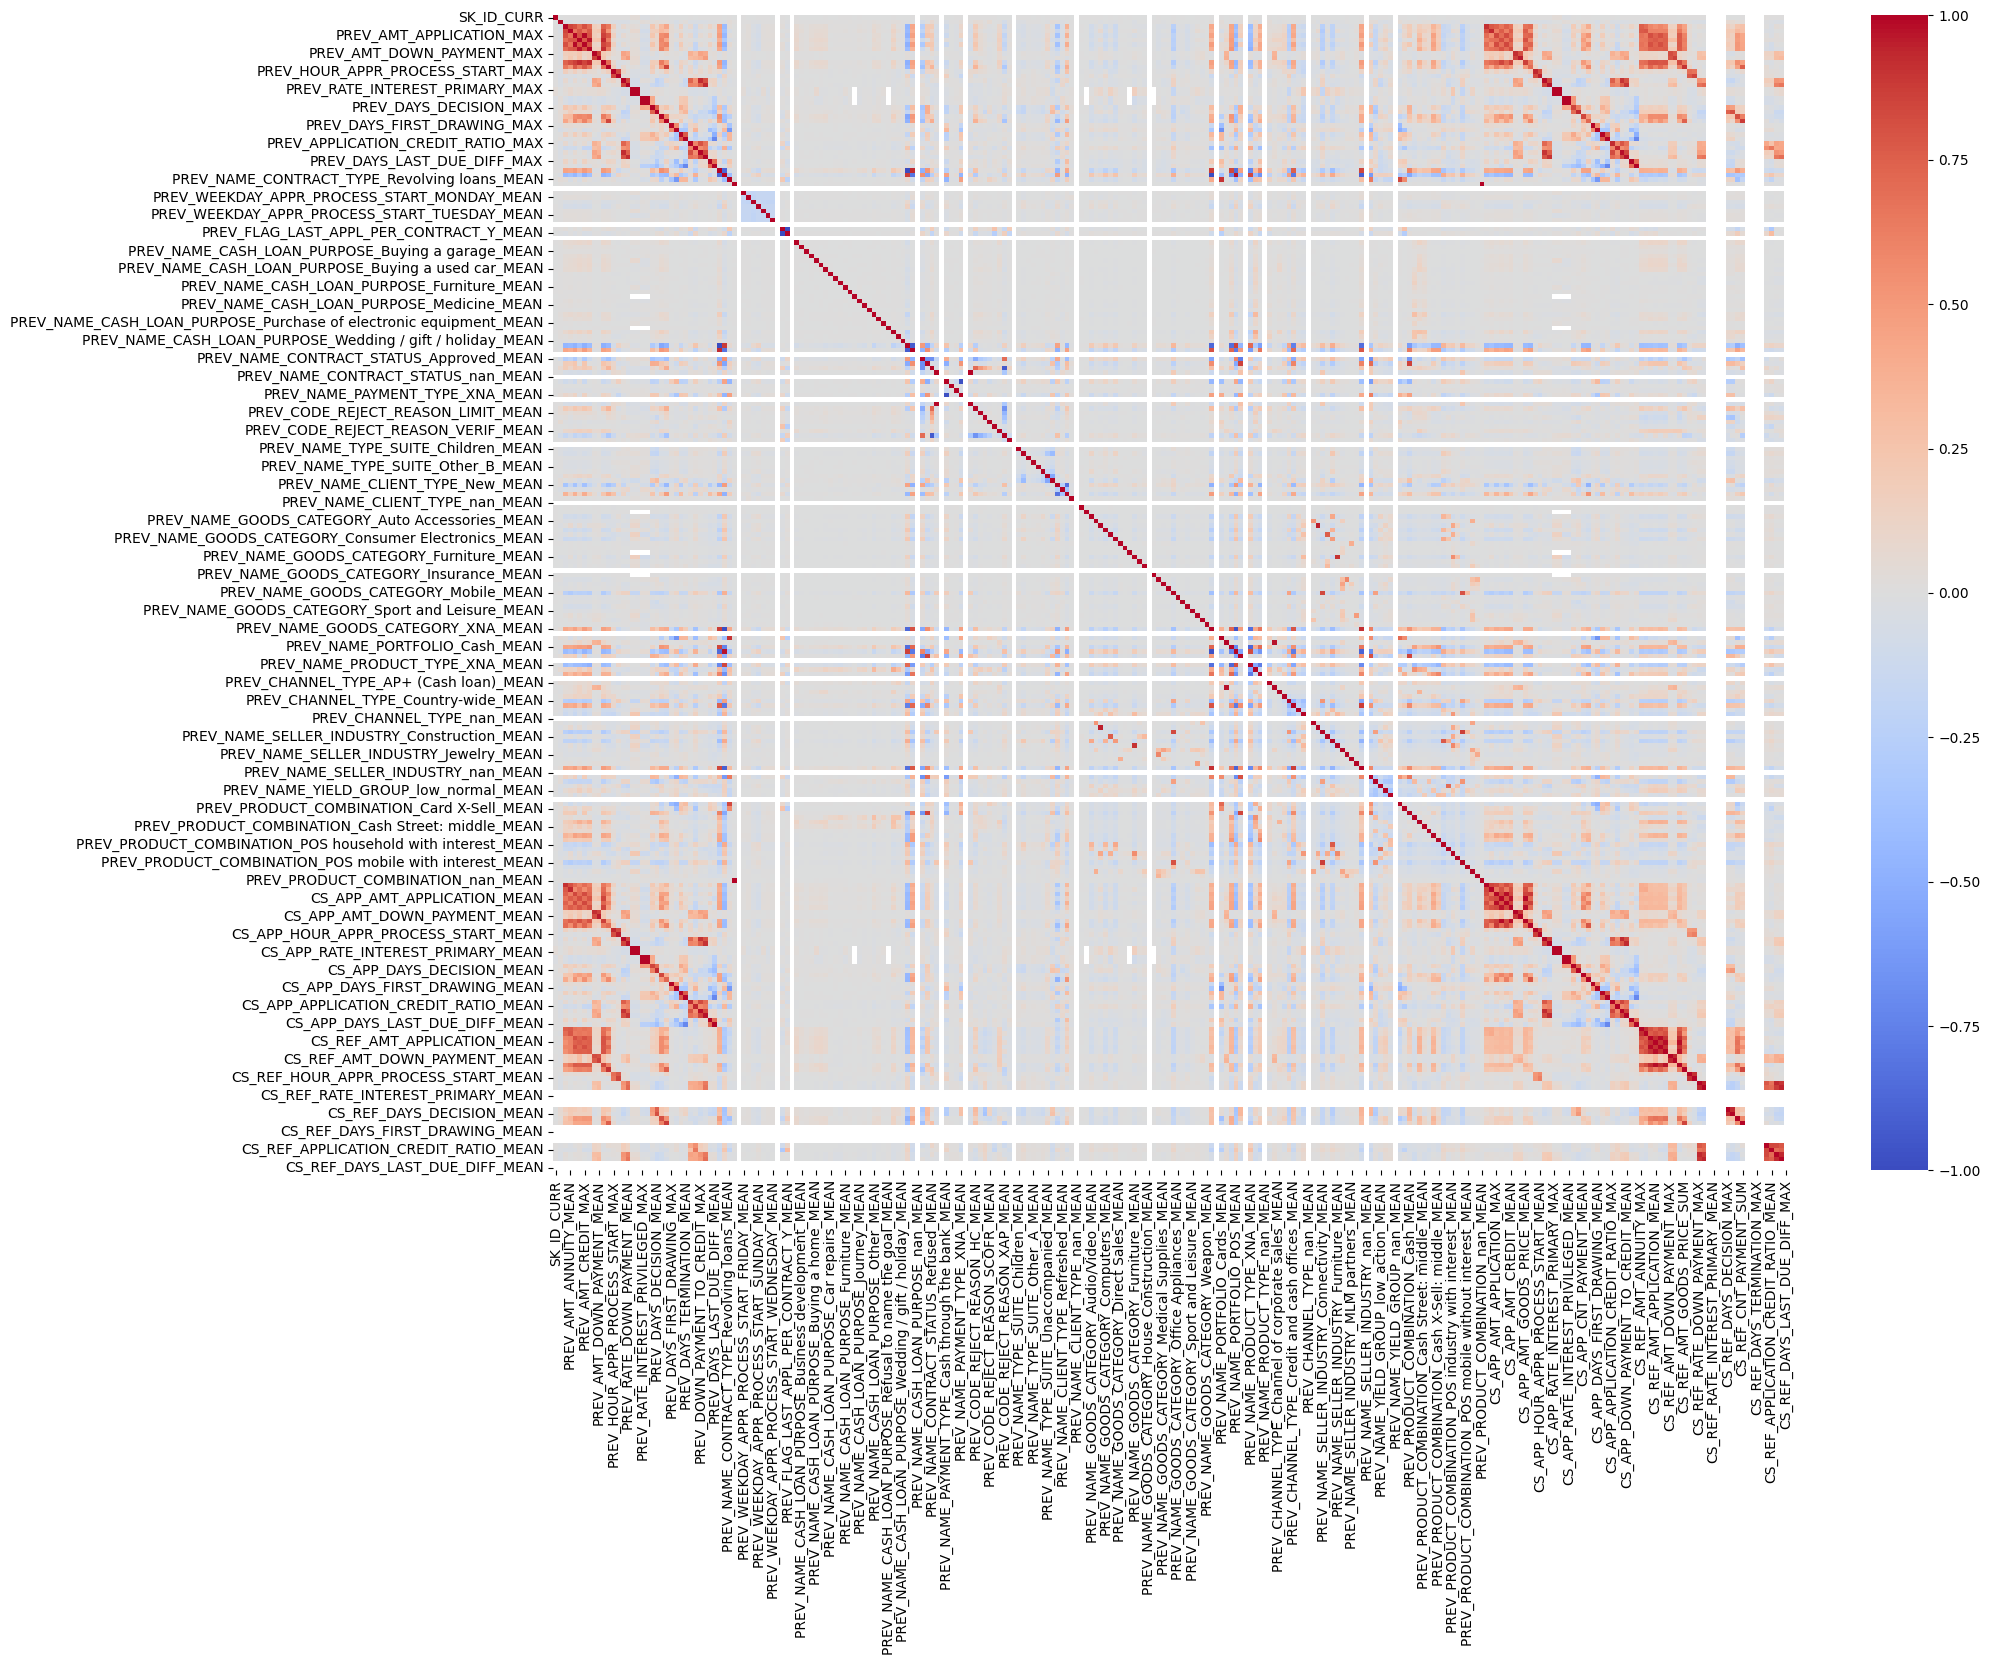

In [ ]:
# Plot correlation matrix
corr = previous_application[num_cols].corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr, cmap='coolwarm')
plt.show()

## Installments payments

In [ ]:
def FE_installments_payments(installments_payments):

    pay1 = installments_payments[['SK_ID_PREV', 'NUM_INSTALMENT_NUMBER']+ ['AMT_PAYMENT']]
    pay2 = pay1.groupby(['SK_ID_PREV', 'NUM_INSTALMENT_NUMBER'])['AMT_PAYMENT'].sum().reset_index()
    pay_final = pay2.rename(columns={'AMT_PAYMENT': 'AMT_PAYMENT_GROUPED'})
    payments_final = installments_payments.merge(pay_final,\
                            on=['SK_ID_PREV','NUM_INSTALMENT_NUMBER'], how='left')

    payments_final['PAYMENT_DIFFERENCE'] = payments_final['AMT_INSTALMENT'] - \
                                       payments_final['AMT_PAYMENT_GROUPED']
    payments_final['PAYMENT_RATIO'] = payments_final['AMT_INSTALMENT'] / payments_final['AMT_PAYMENT_GROUPED']

    payments_final['PAID_OVER_AMOUNT'] = payments_final['AMT_PAYMENT'] - \
                                     payments_final['AMT_INSTALMENT']
    payments_final['PAID_OVER'] = (payments_final['PAID_OVER_AMOUNT'] > 0).astype(int)

    payments_final['DPD'] = payments_final['DAYS_ENTRY_PAYMENT'] - \
                        payments_final['DAYS_INSTALMENT']
    payments_final['DPD'] = payments_final['DPD'].apply(lambda x: 0 if x <= 0 else x)

    payments_final['DBD'] = payments_final['DAYS_INSTALMENT'] - \
                        payments_final['DAYS_ENTRY_PAYMENT']
    payments_final['DBD'] = payments_final['DBD'].apply(lambda x: 0 if x <= 0 else x)
    payments_final['LATE_PAYMENT'] = payments_final['DBD'].apply(lambda x: 1 if x > 0 else 0)

    payments_final['INSTALMENT_PAYMENT_RATIO'] = payments_final['AMT_PAYMENT'] / payments_final['AMT_INSTALMENT']
    payments_final['LATE_PAYMENT_RATIO'] = payments_final.apply(lambda x: x['INSTALMENT_PAYMENT_RATIO'] if x['LATE_PAYMENT'] == 1 else 0, axis=1)

    payments_final['SIGNIFICANT_LATE_PAYMENT'] = payments_final['LATE_PAYMENT_RATIO'].apply(lambda x: 1 if x > 0.05 else 0)

    payments_final['DPD_7'] = payments_final['DPD'].apply(lambda x: 1 if x >= 7 else 0)
    payments_final['DPD_15'] = payments_final['DPD'].apply(lambda x: 1 if x >= 15 else 0)
    payments_final['DPD_30'] = payments_final['DPD'].apply(lambda x: 1 if x >= 30 else 0)
    payments_final['DPD_60'] = payments_final['DPD'].apply(lambda x: 1 if x >= 60 else 0)
    payments_final['DPD_90'] = payments_final['DPD'].apply(lambda x: 1 if x >= 90 else 0)
    payments_final['DPD_180'] = payments_final['DPD'].apply(lambda x: 1 if x >= 180 else 0)
    payments_final['DPD_WOF'] = payments_final['DPD'].apply(lambda x: 1 if x >= 720 else 0)

    payments_final, pay_final_columns = one_hot_encode(payments_final)

    numeric_agg_payments = {'LATE_PAYMENT': ['max','mean','min'],'AMT_PAYMENT': ['min', 'max',\
                      'mean', 'sum'], 'NUM_INSTALMENT_VERSION': ['nunique'], \
                      'NUM_INSTALMENT_NUMBER':['max'], 'AMT_INSTALMENT': ['max', 'mean', 'sum'],
        'PAYMENT_DIFFERENCE': ['max','mean','min','sum'],'DAYS_ENTRY_PAYMENT': ['max', \
        'mean', 'sum'],  'PAID_OVER_AMOUNT': ['max','mean','min']
               }

    for col in pay_final_columns:
        numeric_agg_payments[col] = ['mean']

    payments_final_agg = payments_final.groupby('SK_ID_CURR').agg(numeric_agg_payments)
    col_list_9=[]

    for col in payments_final_agg.columns.tolist():
        col_list_9.append('INS_'+col[0]+'_'+col[1].upper())

    payments_final_agg.columns = pd.Index(col_list_9)
    payments_final_agg['INSTALLATION_COUNT'] = payments_final.groupby('SK_ID_CURR').size()

    del payments_final
    gc.collect()

    return payments_final_agg

In [ ]:
installments_payments = FE_installments_payments(reduce_memory_usage(installments_payments))


Memory usage of dataframe is 311.40 MB
Memory usage after optimization is: 311.40 MB
Decreased by 0.0%


,INS_LATE_PAYMENT_MAX,INS_LATE_PAYMENT_MEAN,INS_LATE_PAYMENT_MIN,INS_AMT_PAYMENT_MIN,INS_AMT_PAYMENT_MAX,INS_AMT_PAYMENT_MEAN,INS_AMT_PAYMENT_SUM,INS_NUM_INSTALMENT_VERSION_NUNIQUE,INS_NUM_INSTALMENT_NUMBER_MAX,INS_AMT_INSTALMENT_MAX,...,INS_PAYMENT_DIFFERENCE_MEAN,INS_PAYMENT_DIFFERENCE_MIN,INS_PAYMENT_DIFFERENCE_SUM,INS_DAYS_ENTRY_PAYMENT_MAX,INS_DAYS_ENTRY_PAYMENT_MEAN,INS_DAYS_ENTRY_PAYMENT_SUM,INS_PAID_OVER_AMOUNT_MAX,INS_PAID_OVER_AMOUNT_MEAN,INS_PAID_OVER_AMOUNT_MIN,INSTALLATION_COUNT
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,
100001,1,0.571429,0,3951.000000,17397.900391,5885.132324,4.119593e+04,2,4,17397.900391,...,0.000000,0.000,0.000,-1628.0,-2195.142822,-15366.0,0.0,0.000000,0.000000,7
100002,1,1.000000,1,9251.775391,53093.746094,11559.247070,2.196257e+05,2,19,53093.746094,...,0.000000,0.000,0.000,-49.0,-315.421051,-5993.0,0.0,0.000000,0.000000,19
100003,1,1.000000,1,6662.970215,560835.375000,64754.585938,1.618865e+06,2,12,560835.375000,...,0.000000,0.000,0.000,-544.0,-1385.359985,-34634.0,0.0,0.000000,0.000000,25
100004,1,1.000000,1,5357.250000,10573.964844,7096.154785,2.128846e+04,2,3,10573.964844,...,0.000000,0.000,0.000,-727.0,-761.666687,-2285.0,0.0,0.000000,0.000000,3
100005,1,0.888889,0,4813.200195,17656.244141,6240.205078,5.616184e+04,2,9,17656.244141,...,0.000000,0.000,0.000,-470.0,-609.555542,-5486.0,0.0,0.000000,0.000000,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
456251,1,1.000000,1,6605.910156,12815.009766,7492.924316,5.245047e+04,2,7,12815.009766,...,0.000000,0.000,0.000,-38.0,-156.285721,-1094.0,0.0,0.000000,0.000000,7
456252,1,0.666667,0,10046.879883,10074.464844,10069.867188,6.041920e+04,1,6,10074.464844,...,0.000000,0.000,0.000,-2328.0,-2393.666748,-14362.0,0.0,0.000000,0.000000,6
456253,1,0.571429,0,27.270000,5575.185059,4115.915039,5.762281e+04,1,12,5575.185059,...,0.000000,0.000,0.000,-1738.0,-2387.714355,-33428.0,0.0,-283.792511,-3945.824951,14


In [ ]:
installments_payments = df.merge(installments_payments, on='SK_ID_CURR', how='left')

In [ ]:
# Bar plot number of missing values column ascending
cols_with_null = installments_payments.isnull().mean()
cols_with_null

SK_ID_CURR                            0.000000
TARGET                                0.000000
INS_LATE_PAYMENT_MAX                  0.051601
INS_LATE_PAYMENT_MEAN                 0.051601
INS_LATE_PAYMENT_MIN                  0.051601
INS_AMT_PAYMENT_MIN                   0.051627
INS_AMT_PAYMENT_MAX                   0.051627
INS_AMT_PAYMENT_MEAN                  0.051627
INS_AMT_PAYMENT_SUM                   0.051601
INS_NUM_INSTALMENT_VERSION_NUNIQUE    0.051601
INS_NUM_INSTALMENT_NUMBER_MAX         0.051601
INS_AMT_INSTALMENT_MAX                0.051601
INS_AMT_INSTALMENT_MEAN               0.051601
INS_AMT_INSTALMENT_SUM                0.051601
INS_PAYMENT_DIFFERENCE_MAX            0.051601
INS_PAYMENT_DIFFERENCE_MEAN           0.051601
INS_PAYMENT_DIFFERENCE_MIN            0.051601
INS_PAYMENT_DIFFERENCE_SUM            0.051601
INS_DAYS_ENTRY_PAYMENT_MAX            0.051627
INS_DAYS_ENTRY_PAYMENT_MEAN           0.051627
INS_DAYS_ENTRY_PAYMENT_SUM            0.051601
INS_PAID_OVER

##  POS Cash Balance Data

In [ ]:
def FE_pos_cash_balance(pos_cash_balance):

    pos_balance_data, pos_balance_columns = one_hot_encode(pos_cash_balance)

    pos_balance_data['LATE_PAYMENT'] = pos_balance_data['SK_DPD'].apply(lambda x:1 \
                                                if x>0 else 0)
    numerical_agg_pos_balance = {'SK_DPD_DEF': ['max', 'mean','min'],'SK_DPD': ['max', 'mean','min'],
        'MONTHS_BALANCE': ['max', 'mean', 'size'], 'CNT_INSTALMENT': ['max','size'],
        'CNT_INSTALMENT_FUTURE': ['max','size','sum']}

    categorical_agg_pos_balance = {}

    for col in pos_balance_columns:
        categorical_agg_pos_balance[col] = ['mean']

    pos_balance_agg = pos_balance_data.groupby('SK_ID_CURR').agg({**numerical_agg_pos_balance, \
                                                    **categorical_agg_pos_balance})
    col_list_8=[]
    for col in pos_balance_agg.columns.tolist():
        col_list_8.append('POS_'+col[0] + '_' + col[1].upper())

    pos_balance_agg.columns = pd.Index(col_list_8)

    sort_pos_balance = pos_balance_data.sort_values(by=['SK_ID_PREV', 'MONTHS_BALANCE'])
    pos_group = sort_pos_balance.groupby('SK_ID_PREV')

    pos_final_df = pd.DataFrame()
    pos_final_df['SK_ID_CURR'] = pos_group['SK_ID_CURR'].first()
    pos_final_df['MONTHS_BALANCE_MAX'] = pos_group['MONTHS_BALANCE'].max()

    pos_final_df['POS_LOAN_COMPLETED_MEAN'] = pos_group['NAME_CONTRACT_STATUS_Completed'].mean()
    pos_final_df['POS_COMPLETED_BEFORE_MEAN'] = pos_group['CNT_INSTALMENT'].first() - \
                                            pos_group['CNT_INSTALMENT'].last()
    pos_final_df['POS_COMPLETED_BEFORE_MEAN'] = pos_final_df.apply(lambda x: 1 if x['POS_COMPLETED_BEFORE_MEAN'] > 0
                                                and x['POS_LOAN_COMPLETED_MEAN'] > 0 else 0, axis=1)

    pos_final_df['POS_REMAINING_INSTALMENTS'] = pos_group['CNT_INSTALMENT_FUTURE'].last()
    pos_final_df['POS_REMAINING_INSTALMENTS_RATIO'] = pos_group['CNT_INSTALMENT_FUTURE'].last()/pos_group['CNT_INSTALMENT'].last()

    pos_final_df_groupby = pos_final_df.groupby('SK_ID_CURR').sum().reset_index()
    pos_final_df_groupby.drop(['MONTHS_BALANCE_MAX'], axis=1, inplace= True)
    pos_final_agg = pd.merge(pos_balance_agg, pos_final_df_groupby, on= 'SK_ID_CURR',\
                         how= 'left')

    del pos_balance_agg, pos_final_df_groupby, pos_group, sort_pos_balance
    gc.collect()
    return pos_final_agg

In [ ]:
pos_cash_balance = df.merge(pos_cash_balance, on='SK_ID_CURR', how='left')

In [ ]:
pos_cash_balance = FE_pos_cash_balance(reduce_memory_usage(pos_cash_balance))
pos_cash_balance

Memory usage of dataframe is 238.45 MB
Memory usage after optimization is: 238.45 MB
Decreased by 0.0%


,SK_ID_CURR,POS_SK_DPD_DEF_MAX,POS_SK_DPD_DEF_MEAN,POS_SK_DPD_DEF_MIN,POS_SK_DPD_MAX,POS_SK_DPD_MEAN,POS_SK_DPD_MIN,POS_MONTHS_BALANCE_MAX,POS_MONTHS_BALANCE_MEAN,POS_MONTHS_BALANCE_SIZE,...,POS_NAME_CONTRACT_STATUS_Completed_MEAN,POS_NAME_CONTRACT_STATUS_Demand_MEAN,POS_NAME_CONTRACT_STATUS_Returned to the store_MEAN,POS_NAME_CONTRACT_STATUS_Signed_MEAN,POS_NAME_CONTRACT_STATUS_XNA_MEAN,POS_NAME_CONTRACT_STATUS_nan_MEAN,POS_LOAN_COMPLETED_MEAN,POS_COMPLETED_BEFORE_MEAN,POS_REMAINING_INSTALMENTS,POS_REMAINING_INSTALMENTS_RATIO
0,100001,7,0.777778,0,7,0.777778,0,-53,-72.555556,9,...,0.222222,0.0,0.0,0.000000,0.0,0.0,0.450000,0,0.0,0.000000
1,100002,0,0.000000,0,0,0.000000,0,-1,-10.000000,19,...,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0,6.0,0.250000
2,100003,0,0.000000,0,0,0.000000,0,-18,-43.785714,28,...,0.071429,0.0,0.0,0.000000,0.0,0.0,0.250000,1,1.0,0.083313
3,100004,0,0.000000,0,0,0.000000,0,-24,-25.500000,4,...,0.250000,0.0,0.0,0.000000,0.0,0.0,0.250000,1,0.0,0.000000
4,100005,0,0.000000,0,0,0.000000,0,-15,-20.000000,11,...,0.090909,0.0,0.0,0.090909,0.0,0.0,0.090909,1,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337247,456251,0,0.000000,0,0,0.000000,0,-1,-5.000000,9,...,0.111111,0.0,0.0,0.111111,0.0,0.0,0.111111,1,0.0,0.000000
337248,456252,0,0.000000,0,0,0.000000,0,-76,-79.000000,7,...,0.142857,0.0,0.0,0.000000,0.0,0.0,0.142857,0,0.0,0.000000
337249,456253,5,0.294118,0,5,0.294118,0,-57,-79.235294,17,...,0.117647,0.0,0.0,0.000000,0.0,0.0,0.416667,0,0.0,0.000000
337250,456254,0,0.000000,0,0,0.000000,0,-1,-5.550000,20,...,0.000000,0.0,0.0,0.000000,0.0,0.0,0.000000,0,12.0,0.785645


In [ ]:
installments_payments

In [ ]:
# Bar plot number of missing values column ascending
cols_with_null = pos_cash_balance.isnull().mean()
cols_with_null

SK_ID_CURR                                             0.000000
POS_SK_DPD_DEF_MAX                                     0.000000
POS_SK_DPD_DEF_MEAN                                    0.000000
POS_SK_DPD_DEF_MIN                                     0.000000
POS_SK_DPD_MAX                                         0.000000
POS_SK_DPD_MEAN                                        0.000000
POS_SK_DPD_MIN                                         0.000000
POS_MONTHS_BALANCE_MAX                                 0.000000
POS_MONTHS_BALANCE_MEAN                                0.000000
POS_MONTHS_BALANCE_SIZE                                0.000000
POS_CNT_INSTALMENT_MAX                                 0.000083
POS_CNT_INSTALMENT_SIZE                                0.000000
POS_CNT_INSTALMENT_FUTURE_MAX                          0.000083
POS_CNT_INSTALMENT_FUTURE_SIZE                         0.000000
POS_CNT_INSTALMENT_FUTURE_SUM                          0.000000
POS_NAME_CONTRACT_STATUS_Active_MEAN    

In [ ]:
num_cols = pos_cash_balance.select_dtypes(include=np.number).columns.tolist()
cat_cols = pos_cash_balance.select_dtypes(include='object').columns.tolist()

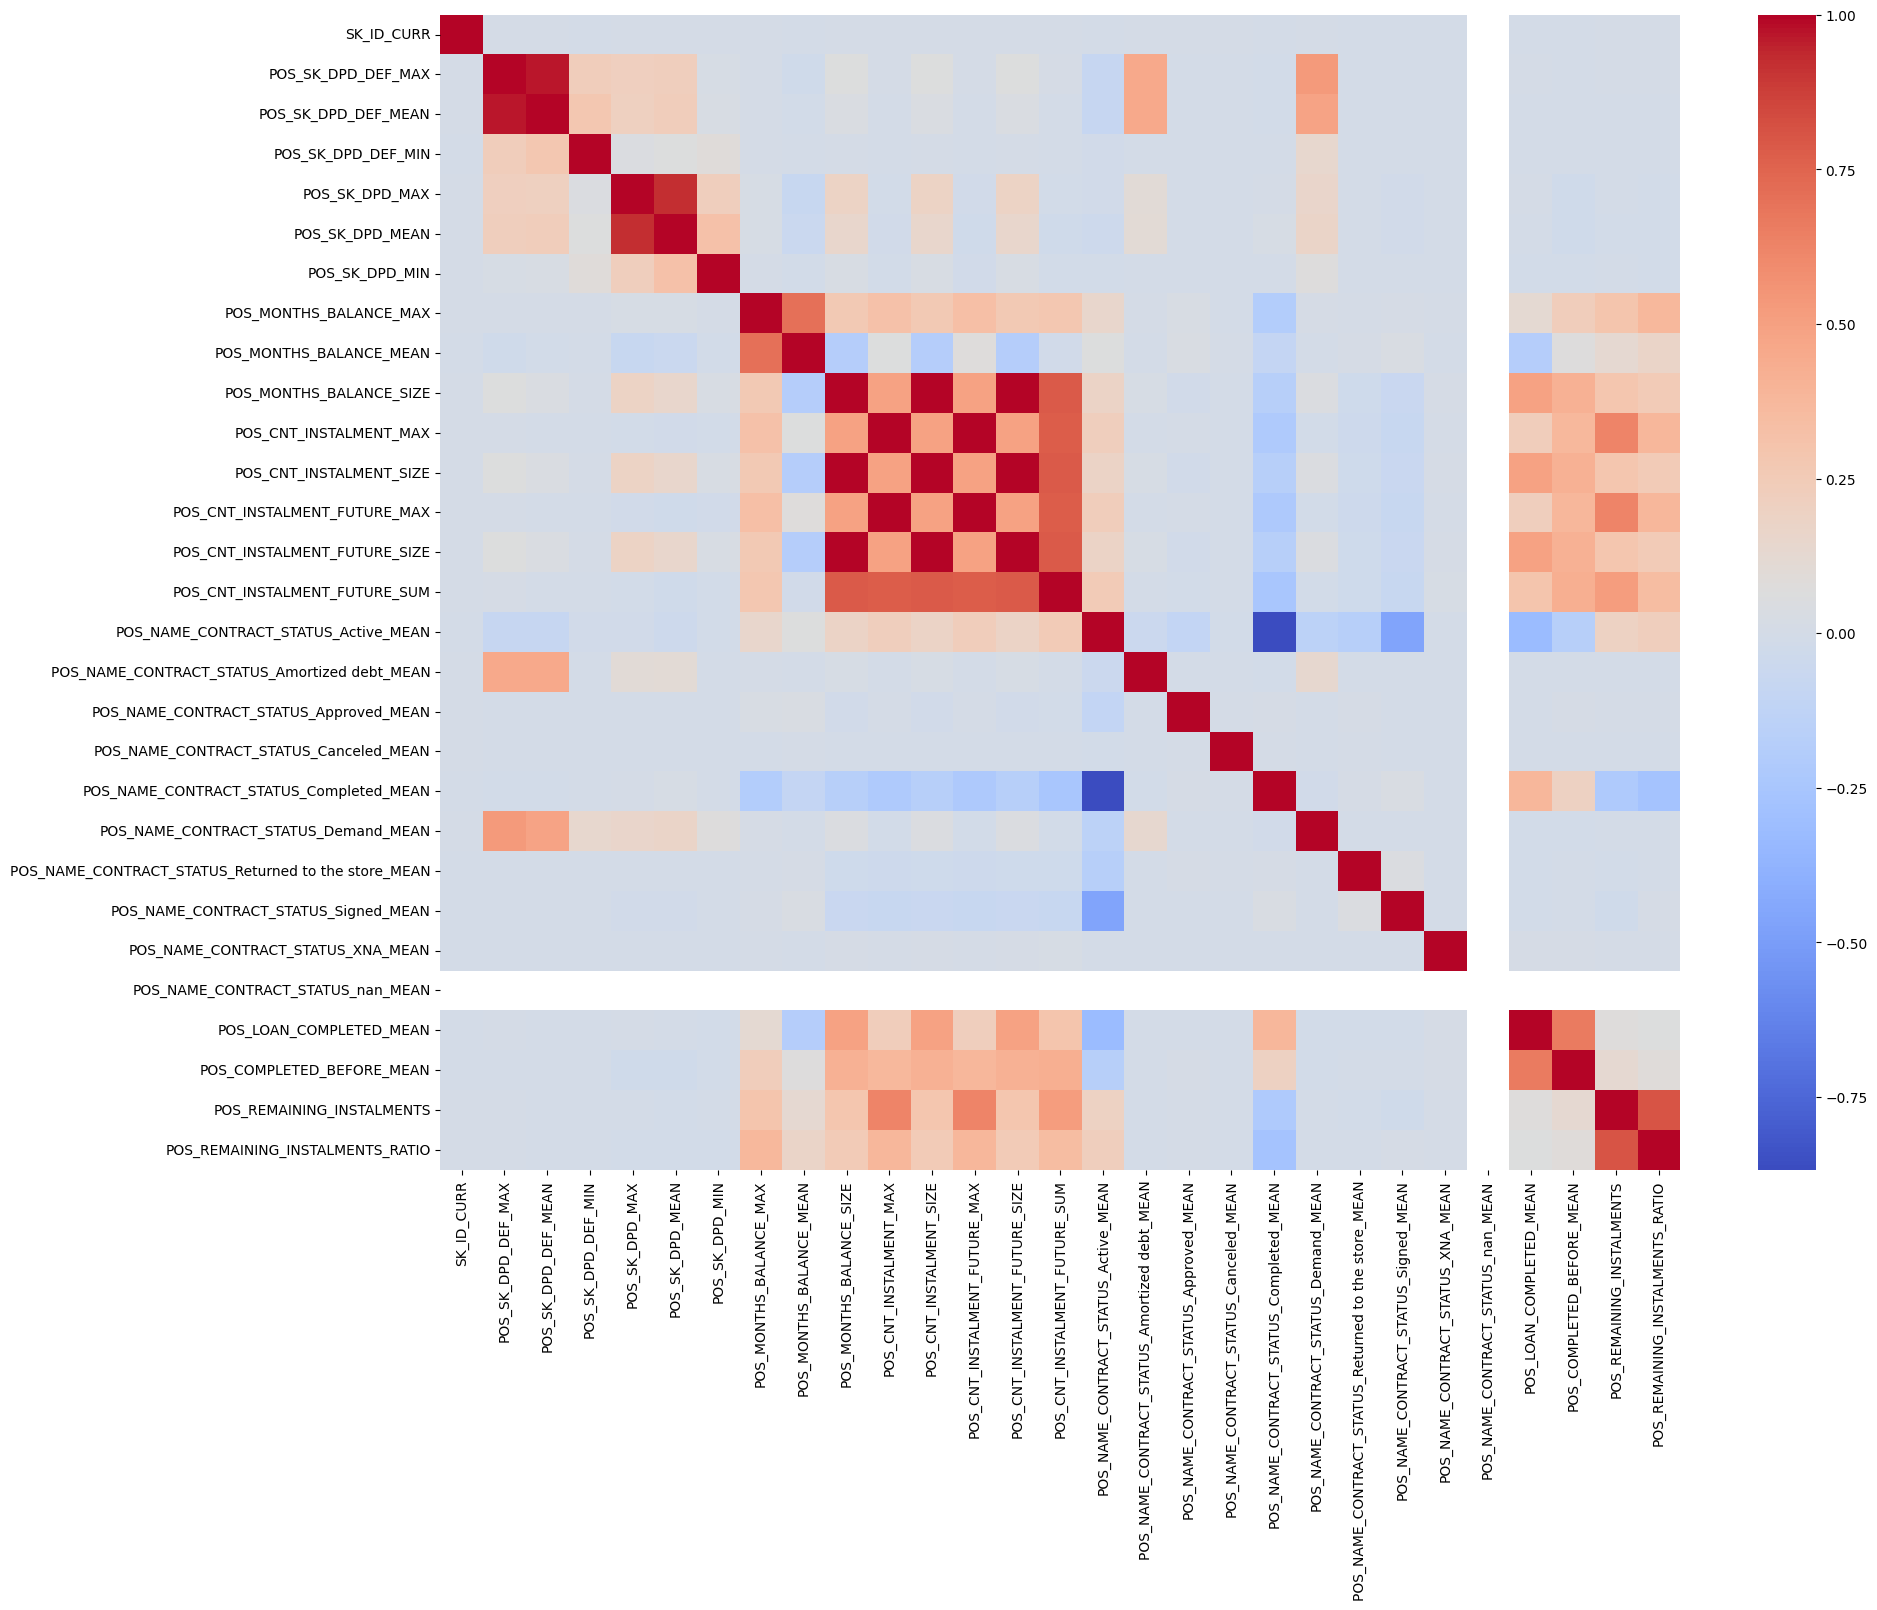

In [ ]:
# Plot correlation matrix
corr = pos_cash_balance[num_cols].corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr, cmap='coolwarm')
plt.show()

## Credit card balanced

In [ ]:
def FE_credit_card_balance(credit_card_balance):

    cc_balance_data, cc_balance_columns = one_hot_encode(credit_card_balance)
    cc_balance_data.rename(columns={'AMT_RECIVABLE': 'AMT_RECEIVABLE'}, inplace=True)

    cc_balance_data['LIMIT_USE'] = cc_balance_data['AMT_BALANCE'] / cc_balance_data['AMT_CREDIT_LIMIT_ACTUAL']
    cc_balance_data['PAYMENT_DIV_MIN'] = cc_balance_data['AMT_PAYMENT_CURRENT'] / cc_balance_data['AMT_INST_MIN_REGULARITY']
    cc_balance_data['LATE_PAYMENT'] = cc_balance_data['SK_DPD'].apply(lambda x: 1 if x > 0 else 0)

    cc_balance_data['DRAWING_LIMIT_RATIO'] = cc_balance_data['AMT_DRAWINGS_ATM_CURRENT'] / cc_balance_data['AMT_CREDIT_LIMIT_ACTUAL']

    cc_balance_data.drop(['SK_ID_PREV'], axis= 1, inplace = True)
    cc_balance_data_agg = cc_balance_data.groupby('SK_ID_CURR').agg(['sum'])

    col_list_9=[]

    for col in cc_balance_data_agg.columns.tolist():
        col_list_9.append('CR_'+col[0]+'_'+col[1].upper())

    cc_balance_data_agg.columns = pd.Index(col_list_9)

    cc_balance_data_agg['CREDIT_COUNT'] = cc_balance_data.groupby('SK_ID_CURR').size()

    del cc_balance_data, cc_balance_columns
    gc.collect()

    return cc_balance_data_agg

In [ ]:
credit_card_balance = FE_credit_card_balance(credit_card_balance)

In [ ]:
credit_card_balance = df.merge(credit_card_balance, on='SK_ID_CURR', how='left')
credit_card_balance

,SK_ID_CURR,TARGET,CR_MONTHS_BALANCE_SUM,CR_AMT_BALANCE_SUM,CR_AMT_CREDIT_LIMIT_ACTUAL_SUM,CR_AMT_DRAWINGS_ATM_CURRENT_SUM,CR_AMT_DRAWINGS_CURRENT_SUM,CR_AMT_DRAWINGS_OTHER_CURRENT_SUM,CR_AMT_DRAWINGS_POS_CURRENT_SUM,CR_AMT_INST_MIN_REGULARITY_SUM,...,CR_NAME_CONTRACT_STATUS_Demand_SUM,CR_NAME_CONTRACT_STATUS_Refused_SUM,CR_NAME_CONTRACT_STATUS_Sent proposal_SUM,CR_NAME_CONTRACT_STATUS_Signed_SUM,CR_NAME_CONTRACT_STATUS_nan_SUM,CR_LIMIT_USE_SUM,CR_PAYMENT_DIV_MIN_SUM,CR_LATE_PAYMENT_SUM,CR_DRAWING_LIMIT_RATIO_SUM,CREDIT_COUNT
0,100002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100003,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100006,0,-21.0,0.0,1620000.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0
4,100007,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
307509,456254,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Bar plot number of missing values column ascending
cols_with_null = credit_card_balance.isnull().mean()
cols_with_null

SK_ID_CURR                                   0.000000
TARGET                                       0.000000
CR_MONTHS_BALANCE_SUM                        0.717392
CR_AMT_BALANCE_SUM                           0.717392
CR_AMT_CREDIT_LIMIT_ACTUAL_SUM               0.717392
CR_AMT_DRAWINGS_ATM_CURRENT_SUM              0.717392
CR_AMT_DRAWINGS_CURRENT_SUM                  0.717392
CR_AMT_DRAWINGS_OTHER_CURRENT_SUM            0.717392
CR_AMT_DRAWINGS_POS_CURRENT_SUM              0.717392
CR_AMT_INST_MIN_REGULARITY_SUM               0.717392
CR_AMT_PAYMENT_CURRENT_SUM                   0.717392
CR_AMT_PAYMENT_TOTAL_CURRENT_SUM             0.717392
CR_AMT_RECEIVABLE_PRINCIPAL_SUM              0.717392
CR_AMT_RECEIVABLE_SUM                        0.717392
CR_AMT_TOTAL_RECEIVABLE_SUM                  0.717392
CR_CNT_DRAWINGS_ATM_CURRENT_SUM              0.717392
CR_CNT_DRAWINGS_CURRENT_SUM                  0.717392
CR_CNT_DRAWINGS_OTHER_CURRENT_SUM            0.717392
CR_CNT_DRAWINGS_POS_CURRENT_

In [ ]:
num_cols = credit_card_balance.select_dtypes(include=np.number).columns.tolist()
cat_cols = credit_card_balance.select_dtypes(include='object').columns.tolist()

cols_to_plot = credit_card_balance[num_cols].var()[credit_card_balance[num_cols].var() > 0.1].index.tolist()
print(f'Plotting {len(cols_to_plot)} columns: {cols_to_plot}')
ncol, nrow = 3, len(cols_to_plot)//3 + 1

Plotting 24 columns: ['SK_ID_CURR', 'CR_MONTHS_BALANCE_SUM', 'CR_AMT_BALANCE_SUM', 'CR_AMT_CREDIT_LIMIT_ACTUAL_SUM', 'CR_AMT_DRAWINGS_ATM_CURRENT_SUM', 'CR_AMT_DRAWINGS_CURRENT_SUM', 'CR_AMT_DRAWINGS_OTHER_CURRENT_SUM', 'CR_AMT_DRAWINGS_POS_CURRENT_SUM', 'CR_AMT_INST_MIN_REGULARITY_SUM', 'CR_AMT_PAYMENT_CURRENT_SUM', 'CR_AMT_PAYMENT_TOTAL_CURRENT_SUM', 'CR_AMT_RECEIVABLE_PRINCIPAL_SUM', 'CR_AMT_RECEIVABLE_SUM', 'CR_AMT_TOTAL_RECEIVABLE_SUM', 'CR_CNT_DRAWINGS_CURRENT_SUM', 'CR_CNT_INSTALMENT_MATURE_CUM_SUM', 'CR_SK_DPD_SUM', 'CR_SK_DPD_DEF_SUM', 'CR_NAME_CONTRACT_STATUS_Active_SUM', 'CR_NAME_CONTRACT_STATUS_Completed_SUM', 'CR_NAME_CONTRACT_STATUS_Demand_SUM', 'CR_NAME_CONTRACT_STATUS_Signed_SUM', 'CR_LATE_PAYMENT_SUM', 'CREDIT_COUNT']


/home/jupyter-iec_roadquality/.local/lib/python3.10/site-packages/numpy/core/_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/home/jupyter-iec_roadquality/.local/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/jupyter-iec_roadquality/.local/lib/python3.10/site-packages/pandas/core/nanops.py:1496: RuntimeWarning: overflow encountered in cast
  return count.astype(dtype, copy=False)
/home/jupyter-iec_roadquality/.local/lib/python3.10/site-packages/numpy/core/_methods.py:49: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
/home/jupyter-iec_roadquality/.local/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/jupyter-ie

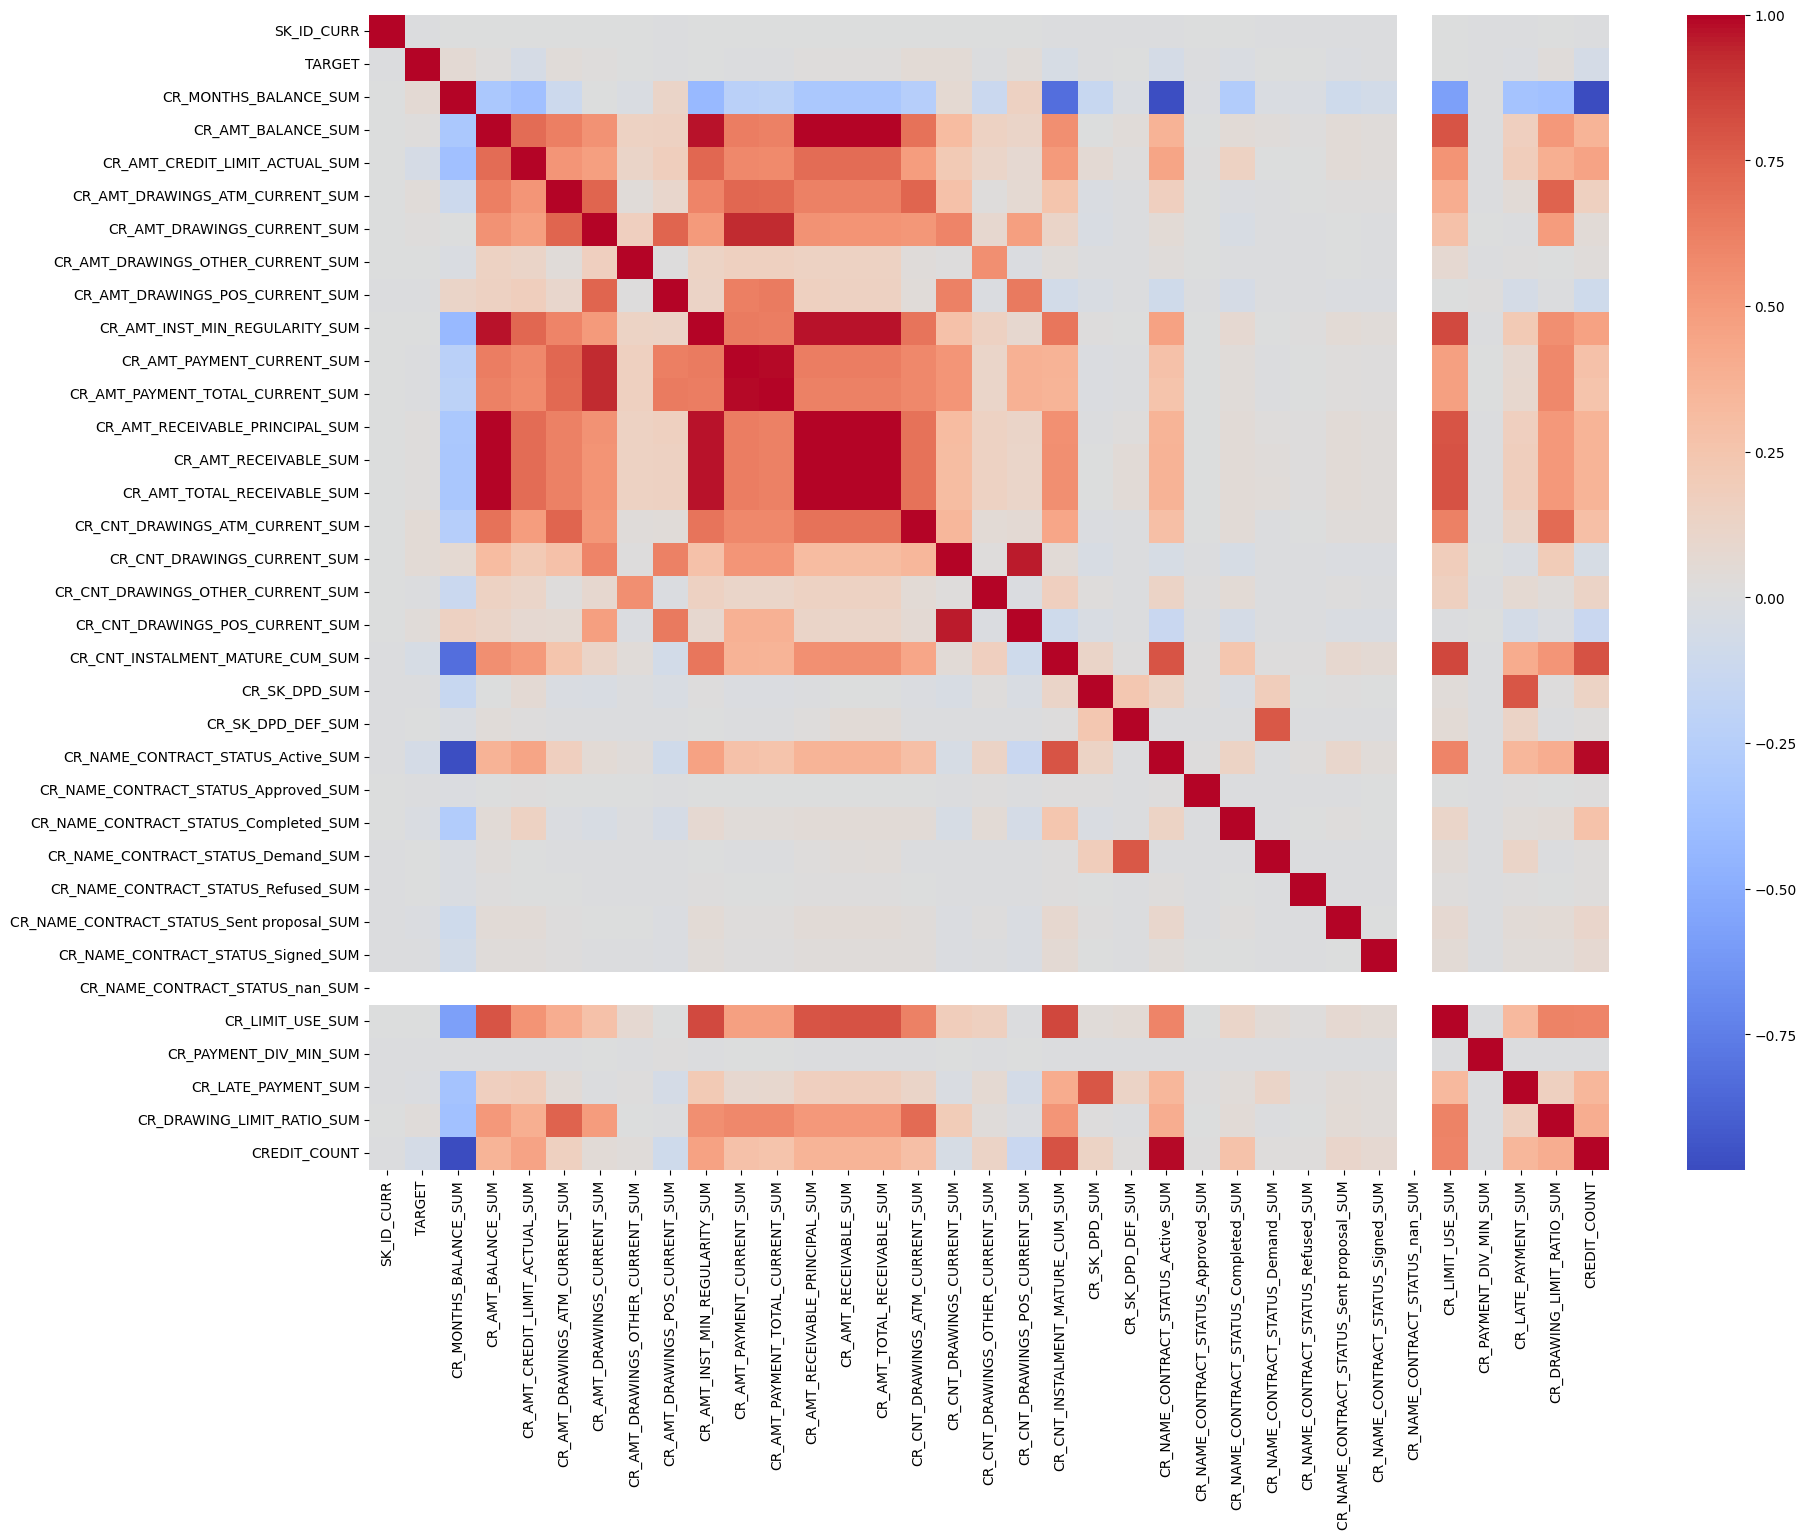

In [ ]:
# Plot correlation matrix
corr = credit_card_balance[num_cols].corr()
plt.figure(figsize=(20, 15))
sns.heatmap(corr, cmap='coolwarm')
plt.show()

## Important feature

In [ ]:
from sklearn.model_selection import KFold
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

def kfold_lightgbm(train_df, test_df=None, num_folds=5, stratified=False, debug=False):
    print("Starting LightGBM. Train shape: {}, test shape: {}".format(train_df.shape, test_df.shape if test_df is not None else "None"))

    feats = [f for f in train_df.columns if f not in ['TARGET', 'SK_ID_CURR']]
    target = train_df['TARGET']

    folds = KFold(n_splits=num_folds, shuffle=True, random_state=47)

    oof_preds = np.zeros(train_df.shape[0])
    sub_preds = np.zeros(test_df.shape[0]) if test_df is not None and not test_df.empty else None

    feature_importance_df = pd.DataFrame()

    for n_fold, (train_idx, valid_idx) in enumerate(folds.split(train_df[feats], target)):
        print(f"Fold {n_fold + 1}")
        train_x, train_y = train_df[feats].iloc[train_idx], target.iloc[train_idx]
        valid_x, valid_y = train_df[feats].iloc[valid_idx], target.iloc[valid_idx]

        clf = LGBMClassifier(
            n_estimators=10000,
            learning_rate=0.02,
            num_leaves=34,
            colsample_bytree=0.9497036,
            subsample=0.8715623,
            max_depth=8,
            reg_alpha=0.041545473,
            reg_lambda=0.0735294,
            min_split_gain=0.0222415,
            min_child_weight=39.3259775,
            silent=-1,
            verbose=-1,
            random_state=47,
            n_jobs=-1
        )

        clf.fit(train_x, train_y,
                eval_set=[(train_x, train_y), (valid_x, valid_y)],
                eval_metric='auc',
                callbacks=[
                    early_stopping(stopping_rounds=200),
                    log_evaluation(period=200)
                ])

        oof_preds[valid_idx] = clf.predict_proba(valid_x, num_iteration=clf.best_iteration_)[:, 1]

        if sub_preds is not None:
            sub_preds += clf.predict_proba(test_df[feats], num_iteration=clf.best_iteration_)[:, 1] / folds.n_splits

        fold_importance_df = pd.DataFrame()
        fold_importance_df["feature"] = feats
        fold_importance_df["importance"] = clf.feature_importances_
        fold_importance_df["fold"] = n_fold + 1
        feature_importance_df = pd.concat([feature_importance_df, fold_importance_df], axis=0)

    print('Full AUC score %.6f' % roc_auc_score(target, oof_preds))

    if not debug:
        if sub_preds is not None:
            submission = test_df[['SK_ID_CURR']].copy()
            submission['TARGET'] = sub_preds
            submission.to_csv('submission_lgb.csv', index=False)

    return feature_importance_df


In [ ]:
def encode_categorical_columns(df):
    """
    Chuyển tất cả các cột object/category trong DataFrame thành số nguyên.
    """
    for col in df.columns:
        if df[col].dtype == 'object' or str(df[col].dtype) == 'category':
            df[col], _ = pd.factorize(df[col])
    return df

# Áp dụng cho tất cả các bảng
application = encode_categorical_columns(application)
bureau = encode_categorical_columns(bureau)
installments_payments = encode_categorical_columns(installments_payments)
pos_cash_balance = encode_categorical_columns(pos_cash_balance)
credit_card_balance = encode_categorical_columns(credit_card_balance)
previous_application = encode_categorical_columns(previous_application)

In [ ]:
application.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,PHONE_CHANGE_BIRTH_PERCENT,MEDIAN_INCOME_CONTRACT_TYPE,MEDIAN_INCOME_SUITE_TYPE,MEDIAN_INCOME_HOUSING_TYPE,MEDIAN_INCOME_ORG_TYPE,MEDIAN_INCOME_OCCU_TYPE,MEDIAN_INCOME_EDU_TYPE,ORG_TYPE_INCOME_PERCENT,OCCU_TYPE_INCOME_PERCENT,EDU_TYPE_INCOME_PERCENT
0,100002,1,0,0,0,0,0,202500.0,406597.5,24700.5,...,0.119860,153000.0,153000.0,148500.0,157500.0,157500.0,135000.0,0.777778,0.777778,0.666667
1,100003,0,0,1,0,1,0,270000.0,1293502.5,35698.5,...,0.049389,153000.0,144000.0,148500.0,135000.0,157500.0,180000.0,0.500000,0.583333,0.666667
2,100004,0,1,0,1,0,0,67500.0,135000.0,6750.0,...,0.042791,135000.0,153000.0,148500.0,135000.0,157500.0,135000.0,2.000000,2.333333,2.000000
3,100006,0,0,1,0,0,0,135000.0,312682.5,29686.5,...,0.032465,153000.0,153000.0,148500.0,157500.0,157500.0,135000.0,1.166667,1.166667,1.000000
4,100007,0,0,0,0,0,0,121500.0,513000.0,21865.5,...,0.055489,153000.0,153000.0,148500.0,162000.0,157500.0,135000.0,1.333333,1.296296,1.111111


In [ ]:
train_df = application[application['TARGET'].notnull()]
test_df = application[application['TARGET'].isnull()]
feat_importance = kfold_lightgbm(train_df, test_df=test_df, num_folds=10, stratified=False, debug=False)

Starting LightGBM. Train shape: (307511, 129), test shape: (0, 129)
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.775505	training's binary_logloss: 0.241614	valid_1's auc: 0.760865	valid_1's binary_logloss: 0.247621
[400]	training's auc: 0.792956	training's binary_logloss: 0.235489	valid_1's auc: 0.769262	valid_1's binary_logloss: 0.244825
[600]	training's auc: 0.805216	training's binary_logloss: 0.231394	valid_1's auc: 0.771013	valid_1's binary_logloss: 0.244262
[800]	training's auc: 0.815792	training's binary_logloss: 0.22779	valid_1's auc: 0.772186	valid_1's binary_logloss: 0.243878
[1000]	training's auc: 0.825092	training's binary_logloss: 0.224516	valid_1's auc: 0.772199	valid_1's binary_logloss: 0.243802
Early stopping, best iteration is:
[864]	training's auc: 0.818913	training's binary_logloss: 0.226685	valid_1's auc: 0.772541	valid_1's binary_logloss: 0.243769
Fold 2
Training until validation scores don't improve for 200 rounds
[20

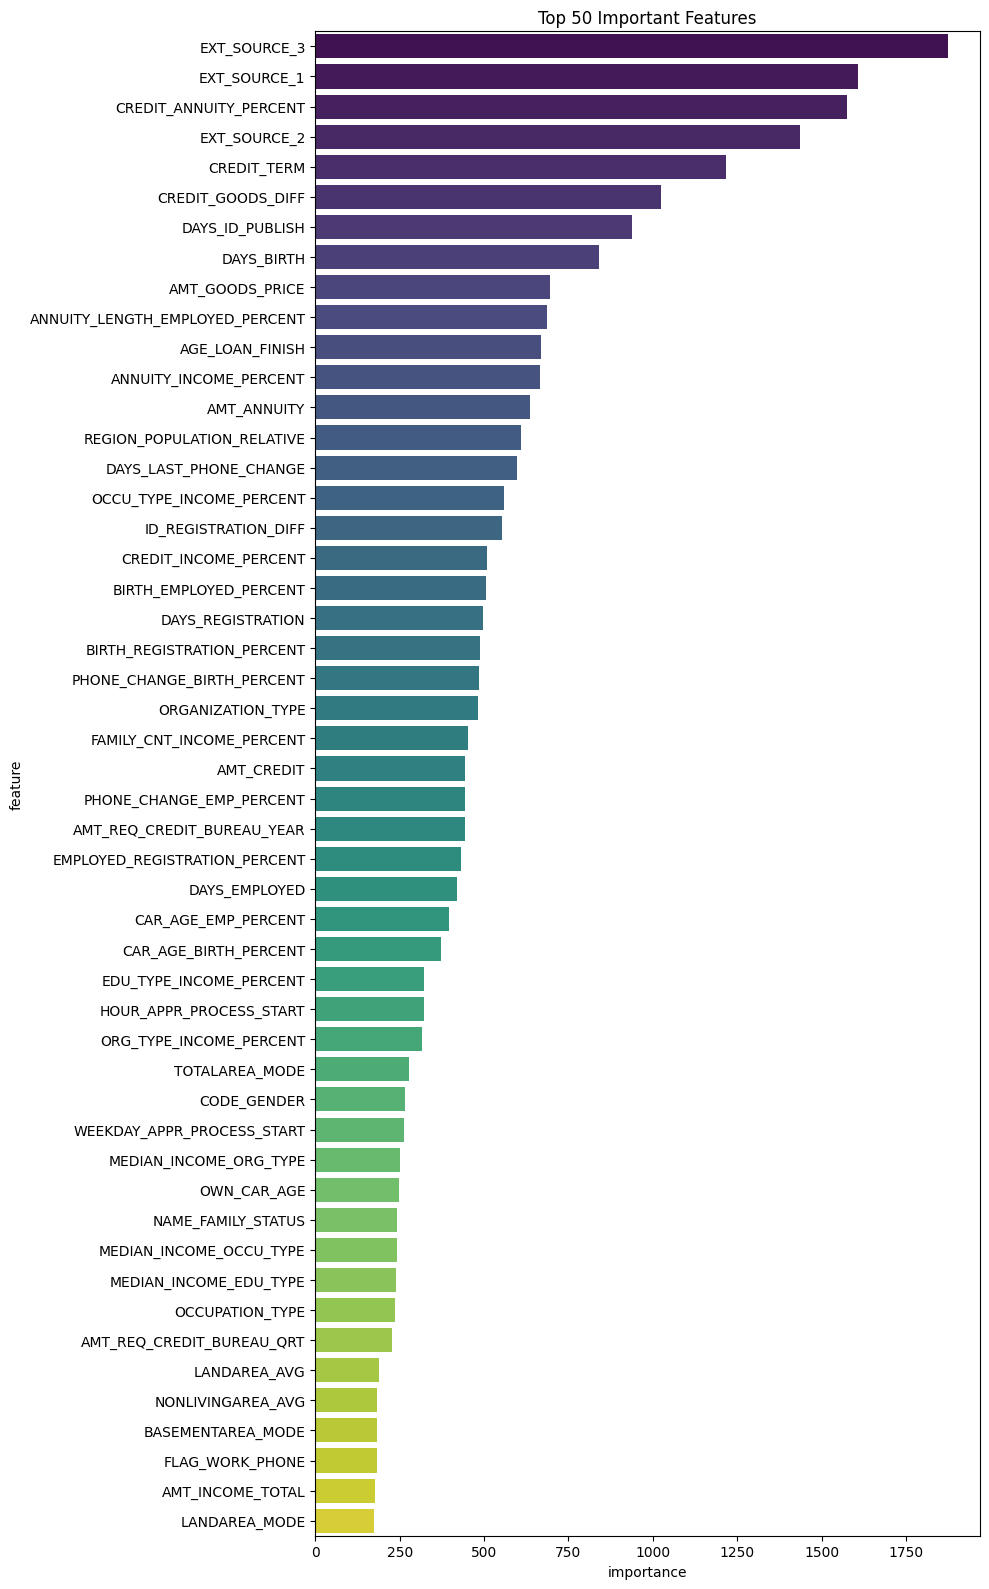

In [ ]:
# Lấy top 50 feature quan trọng nhất
top_feats_application = feat_importance.groupby("feature").mean().reset_index()
top_feats_application  = top_feats_application.sort_values(by="importance", ascending=False).head(50)

plt.figure(figsize=(10, 16))
sns.barplot(
    data=top_feats_application ,
    y="feature",
    x="importance",
    palette="viridis"
)
plt.title("Top 50 Important Features")
plt.tight_layout()
plt.show()


In [ ]:
top_feats_application

,feature,importance,fold
52,EXT_SOURCE_3,1875.7,5.5
50,EXT_SOURCE_1,1607.7,5.5
30,CREDIT_ANNUITY_PERCENT,1574.5,5.5
51,EXT_SOURCE_2,1436.3,5.5
33,CREDIT_TERM,1217.2,5.5
31,CREDIT_GOODS_DIFF,1025.4,5.5
36,DAYS_ID_PUBLISH,938.3,5.5
34,DAYS_BIRTH,840.6,5.5
3,AMT_GOODS_PRICE,696.8,5.5
12,ANNUITY_LENGTH_EMPLOYED_PERCENT,687.8,5.5


In [ ]:
important_features = (
    feat_importance.groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
)

print("Danh sách các feature quan trọng giảm dần:")
for i, f in enumerate(important_features.index.tolist()):
    print(f"{i+1}. {f}")


Danh sách các feature quan trọng giảm dần:
1. EXT_SOURCE_3
2. EXT_SOURCE_1
3. CREDIT_ANNUITY_PERCENT
4. EXT_SOURCE_2
5. CREDIT_TERM
6. CREDIT_GOODS_DIFF
7. DAYS_ID_PUBLISH
8. DAYS_BIRTH
9. AMT_GOODS_PRICE
10. ANNUITY_LENGTH_EMPLOYED_PERCENT
11. AGE_LOAN_FINISH
12. ANNUITY_INCOME_PERCENT
13. AMT_ANNUITY
14. REGION_POPULATION_RELATIVE
15. DAYS_LAST_PHONE_CHANGE
16. OCCU_TYPE_INCOME_PERCENT
17. ID_REGISTRATION_DIFF
18. CREDIT_INCOME_PERCENT
19. BIRTH_EMPLOYED_PERCENT
20. DAYS_REGISTRATION
21. BIRTH_REGISTRATION_PERCENT
22. PHONE_CHANGE_BIRTH_PERCENT
23. ORGANIZATION_TYPE
24. FAMILY_CNT_INCOME_PERCENT
25. AMT_CREDIT
26. PHONE_CHANGE_EMP_PERCENT
27. AMT_REQ_CREDIT_BUREAU_YEAR
28. EMPLOYED_REGISTRATION_PERCENT
29. DAYS_EMPLOYED
30. CAR_AGE_EMP_PERCENT
31. CAR_AGE_BIRTH_PERCENT
32. EDU_TYPE_INCOME_PERCENT
33. HOUR_APPR_PROCESS_START
34. ORG_TYPE_INCOME_PERCENT
35. TOTALAREA_MODE
36. CODE_GENDER
37. WEEKDAY_APPR_PROCESS_START
38. MEDIAN_INCOME_ORG_TYPE
39. OWN_CAR_AGE
40. NAME_FAMILY_STATUS
41

In [ ]:
train_bureau = bureau[bureau['TARGET'].notnull()]
test_bureau = bureau[bureau['TARGET'].isnull()]
feat_importance = kfold_lightgbm(train_bureau, test_bureau, num_folds=10, stratified=False, debug=False)

Starting LightGBM. Train shape: (307511, 99), test shape: (0, 99)
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.680551	training's binary_logloss: 0.26428	valid_1's auc: 0.659011	valid_1's binary_logloss: 0.26948
[400]	training's auc: 0.695647	training's binary_logloss: 0.261106	valid_1's auc: 0.661599	valid_1's binary_logloss: 0.268872
[600]	training's auc: 0.708362	training's binary_logloss: 0.258633	valid_1's auc: 0.662252	valid_1's binary_logloss: 0.26882
Early stopping, best iteration is:
[443]	training's auc: 0.699027	training's binary_logloss: 0.260473	valid_1's auc: 0.662666	valid_1's binary_logloss: 0.268808
Fold 2
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.681394	training's binary_logloss: 0.263892	valid_1's auc: 0.653618	valid_1's binary_logloss: 0.271952
[400]	training's auc: 0.696503	training's binary_logloss: 0.260737	valid_1's auc: 0.655002	valid_1's binary_logloss: 0.271626
[600]	tr

In [ ]:
important_features = (
    feat_importance.groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
)

print("Danh sách các feature quan trọng giảm dần:")
for i, f in enumerate(important_features.index.tolist()):
    print(f"{i+1}. {f}")


Danh sách các feature quan trọng giảm dần:
1. BUREAU_AMT_CREDIT_SUM_mean
2. BUREAU_DAYS_CREDIT_mean
3. BUREAU_AMT_CREDIT_SUM_DEBT_sum
4. BUREAU_DAYS_CREDIT_ENDDATE_mean
5. BUREAU_DAYS_CREDIT_var
6. BUREAU_AMT_CREDIT_SUM_DEBT_mean
7. BUREAU_AMT_CREDIT_SUM_max
8. BUREAU_AMT_CREDIT_SUM_LIMIT_mean
9. C_DAYS_CREDIT_ENDDATE_MEAN
10. C_AMT_CREDIT_SUM_MEAN
11. BUREAU_AMT_CREDIT_SUM_sum
12. BUREAU_AMT_CREDIT_MAX_OVERDUE_mean
13. C_DAYS_CREDIT_VAR
14. C_DAYS_CREDIT_UPDATE_MEAN
15. BUREAU_AMT_CREDIT_MAX_OVERDUE_max
16. C_AMT_CREDIT_SUM_SUM
17. C_DAYS_CREDIT_MEAN
18. BUREAU_STATUS_1_MEAN_mean
19. C_AMT_CREDIT_SUM_MAX
20. BUREAU_DAYS_CREDIT_UPDATE_mean
21. BUREAU_STATUS_0_MEAN_mean
22. C_DAYS_CREDIT_UPDATE_MIN
23. BUREAU_DAYS_CREDIT_UPDATE_min
24. C_AMT_CREDIT_MAX_OVERDUE_MAX
25. BUREAU_STATUS_X_MEAN_mean
26. C_AMT_CREDIT_MAX_OVERDUE_MEAN
27. BUREAU_AMT_CREDIT_SUM_LIMIT_sum
28. BUREAU_STATUS_C_MEAN_mean
29. BUREAU_AMT_ANNUITY_mean
30. BUREAU_AMT_ANNUITY_max
31. BUREAU_CREDIT_TYPE_Microloan_max
32. 

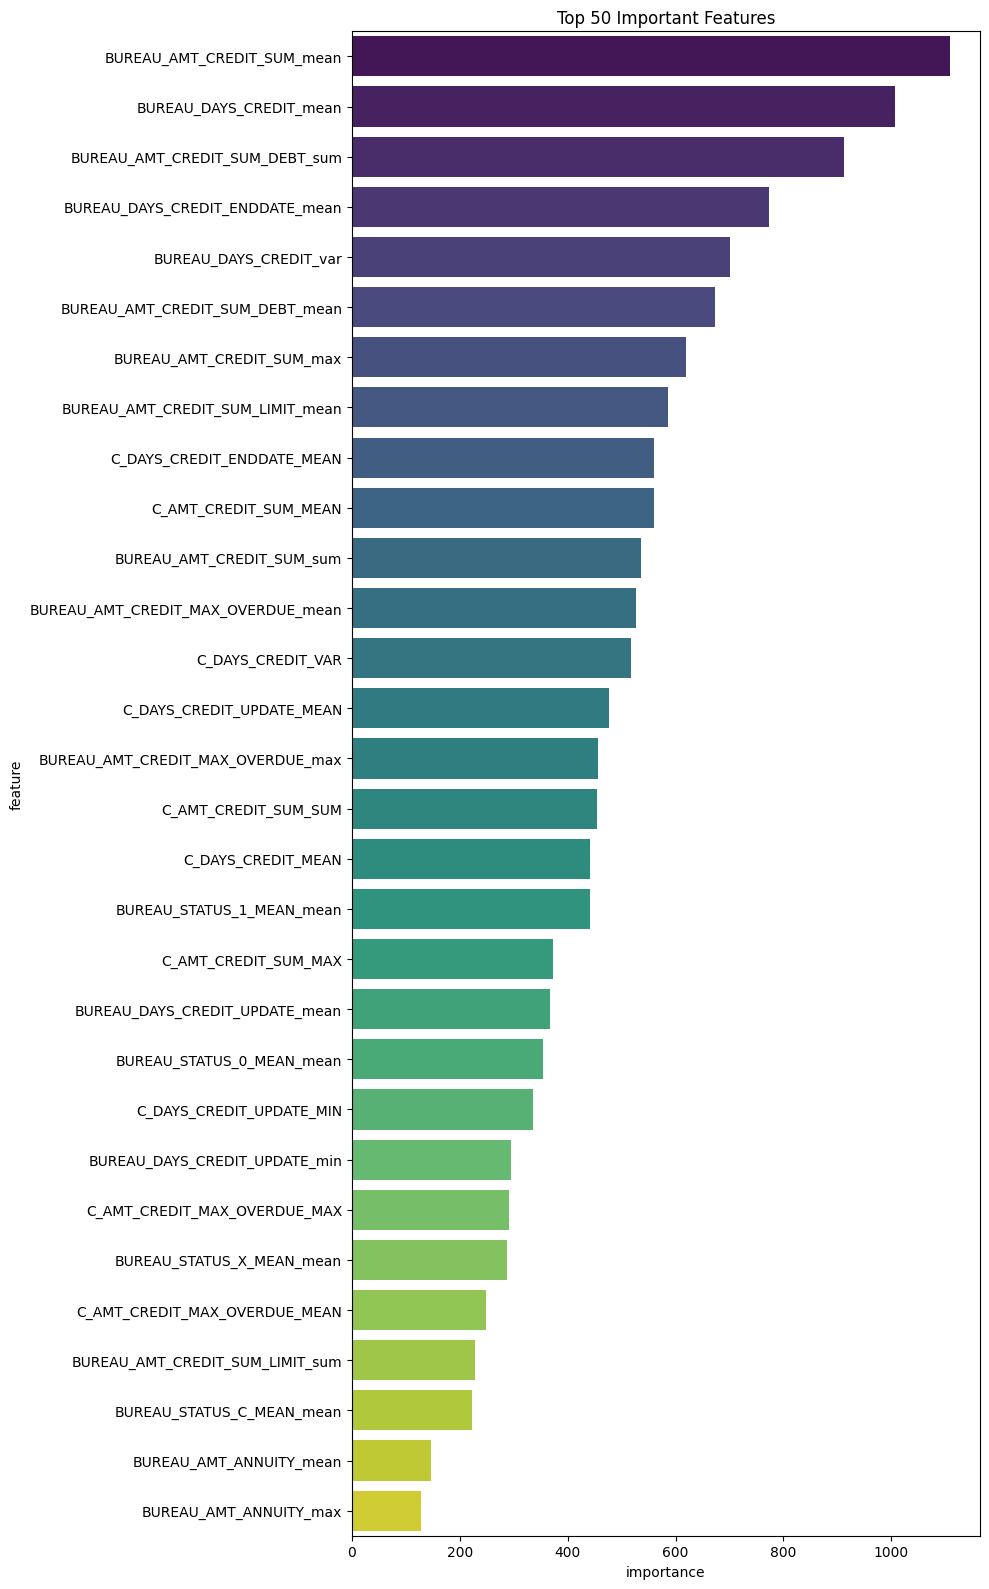

In [ ]:
# Lấy top 30 feature quan trọng nhất
top_feats_bureau = feat_importance.groupby("feature").mean().reset_index()
top_feats_bureau  = top_feats_bureau.sort_values(by="importance", ascending=False).head(30)

plt.figure(figsize=(10, 16))
sns.barplot(
    data=top_feats_bureau,
    y="feature",
    x="importance",
    palette="viridis"
)
plt.title("Top 50 Important Features")
plt.tight_layout()
plt.show()


In [ ]:
top_feats_bureau

,feature,importance,fold
12,BUREAU_AMT_CREDIT_SUM_mean,1108.9,5.5
46,BUREAU_DAYS_CREDIT_mean,1007.6,5.5
6,BUREAU_AMT_CREDIT_SUM_DEBT_sum,911.6,5.5
43,BUREAU_DAYS_CREDIT_ENDDATE_mean,773.6,5.5
47,BUREAU_DAYS_CREDIT_var,701.8,5.5
5,BUREAU_AMT_CREDIT_SUM_DEBT_mean,672.4,5.5
11,BUREAU_AMT_CREDIT_SUM_max,619.7,5.5
7,BUREAU_AMT_CREDIT_SUM_LIMIT_mean,585.5,5.5
92,C_DAYS_CREDIT_ENDDATE_MEAN,560.6,5.5
85,C_AMT_CREDIT_SUM_MEAN,559.3,5.5


In [ ]:
train_installments = installments_payments[installments_payments['TARGET'].notnull()]
test_installments = installments_payments[installments_payments['TARGET'].isnull()]
feat_importance_installments_payments = kfold_lightgbm(train_installments, test_installments, num_folds=10, stratified=False, debug=False)

Starting LightGBM. Train shape: (307511, 25), test shape: (0, 25)
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.666358	training's binary_logloss: 0.266677	valid_1's auc: 0.63857	valid_1's binary_logloss: 0.272603
[400]	training's auc: 0.679528	training's binary_logloss: 0.264386	valid_1's auc: 0.639052	valid_1's binary_logloss: 0.272434
[600]	training's auc: 0.688401	training's binary_logloss: 0.262811	valid_1's auc: 0.638607	valid_1's binary_logloss: 0.272474
Early stopping, best iteration is:
[421]	training's auc: 0.680451	training's binary_logloss: 0.264219	valid_1's auc: 0.639156	valid_1's binary_logloss: 0.272414
Fold 2
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.666053	training's binary_logloss: 0.266546	valid_1's auc: 0.640299	valid_1's binary_logloss: 0.273696
[400]	training's auc: 0.679489	training's binary_logloss: 0.264198	valid_1's auc: 0.642192	valid_1's binary_logloss: 0.273454
[600]	

In [ ]:
feat_importance_installments_payments

feature
INS_DAYS_ENTRY_PAYMENT_MAX            1032.0
INS_AMT_PAYMENT_MIN                    867.9
INS_DAYS_ENTRY_PAYMENT_MEAN            866.7
INS_AMT_INSTALMENT_MAX                 771.7
INS_NUM_INSTALMENT_NUMBER_MAX          751.8
INS_AMT_PAYMENT_SUM                    749.4
INS_AMT_PAYMENT_MEAN                   708.2
INS_LATE_PAYMENT_MEAN                  684.1
INS_DAYS_ENTRY_PAYMENT_SUM             619.4
INS_AMT_PAYMENT_MAX                    616.7
INS_PAID_OVER_AMOUNT_MIN               560.8
INS_AMT_INSTALMENT_MEAN                489.6
INS_AMT_INSTALMENT_SUM                 487.8
INS_PAID_OVER_AMOUNT_MEAN              477.3
INSTALLATION_COUNT                     379.1
INS_NUM_INSTALMENT_VERSION_NUNIQUE     352.9
INS_PAYMENT_DIFFERENCE_SUM             290.6
INS_PAYMENT_DIFFERENCE_MEAN            256.8
INS_PAYMENT_DIFFERENCE_MAX             224.1
INS_PAID_OVER_AMOUNT_MAX               116.8
INS_PAYMENT_DIFFERENCE_MIN              88.3
INS_LATE_PAYMENT_MIN                     2.3
IN

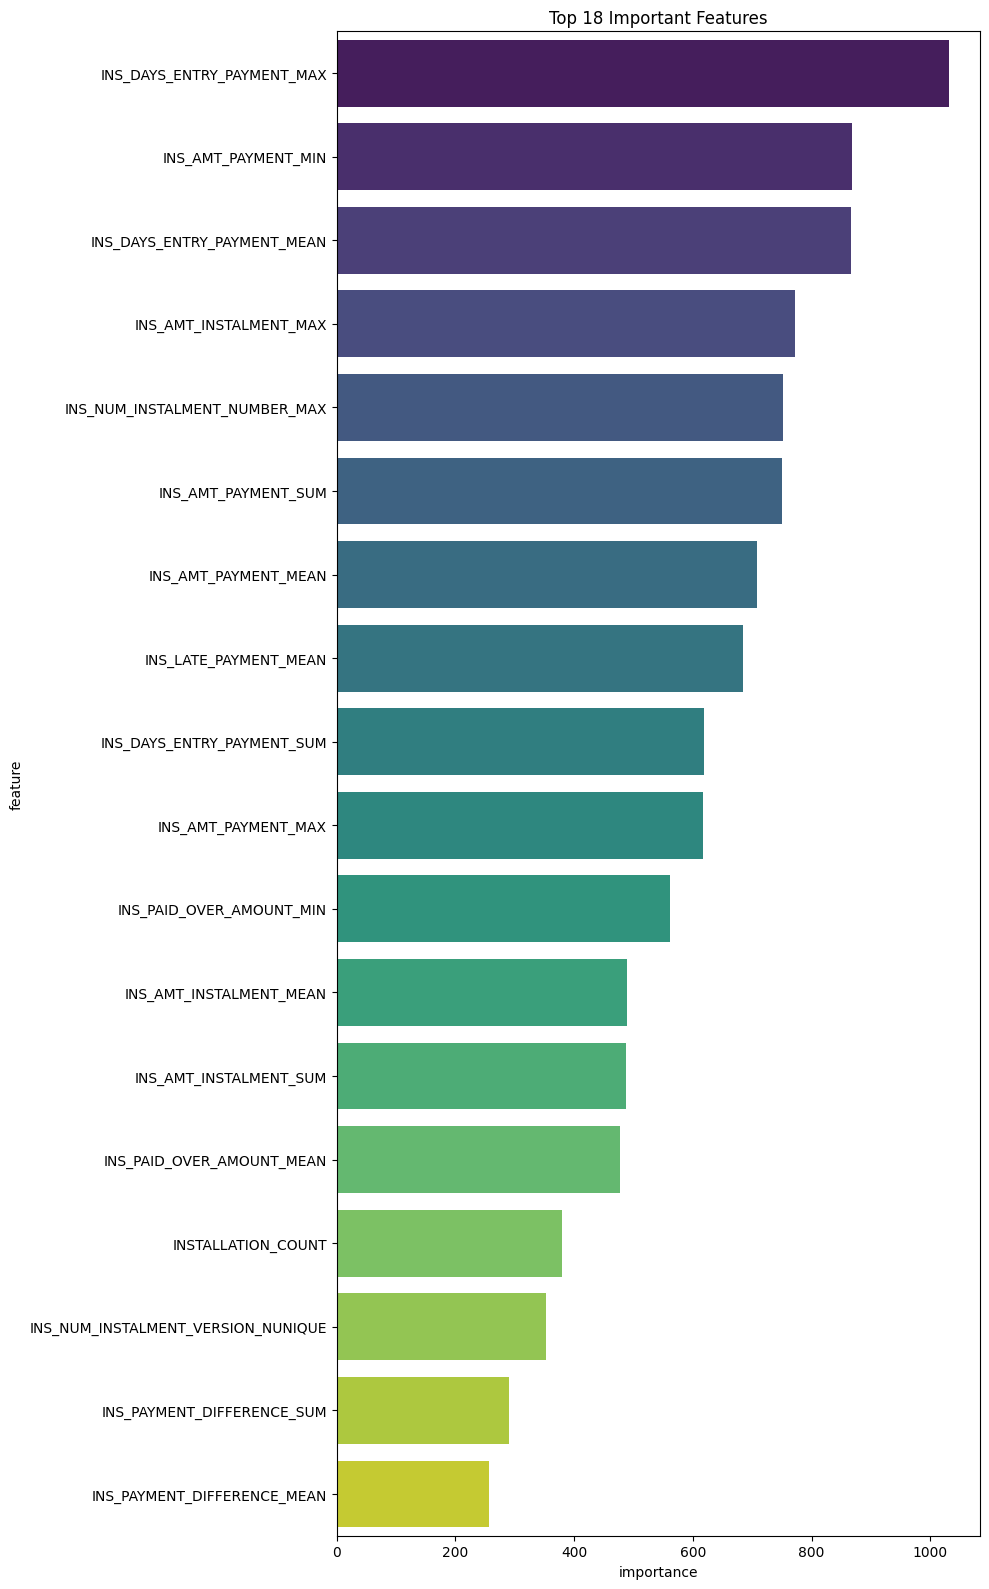

In [ ]:
# Lấy top 18 feature quan trọng nhất
top_feats_installments_payments = feat_importance_installments_payments.groupby("feature").mean().reset_index()
top_feats_installments_payments  = feat_importance_installments_payments.sort_values(by="importance", ascending=False).head(18)

plt.figure(figsize=(10, 16))
sns.barplot(
    data=top_feats_installments_payments,
    y="feature",
    x="importance",
    palette="viridis"
)
plt.title("Top 18 Important Features")
plt.tight_layout()
plt.show()


In [ ]:
train_pos_cash = pos_cash_balance[pos_cash_balance['TARGET'].notnull()]
test_pos_cash = pos_cash_balance[pos_cash_balance['TARGET'].isnull()]
feat_importance_pos_cash_balance = kfold_lightgbm(train_pos_cash, test_pos_cash, num_folds=10, stratified=False, debug=False)

Starting LightGBM. Train shape: (307511, 30), test shape: (0, 30)
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.630957	training's binary_logloss: 0.271763	valid_1's auc: 0.602138	valid_1's binary_logloss: 0.27668
[400]	training's auc: 0.643428	training's binary_logloss: 0.269958	valid_1's auc: 0.601933	valid_1's binary_logloss: 0.276721
Early stopping, best iteration is:
[216]	training's auc: 0.632098	training's binary_logloss: 0.271592	valid_1's auc: 0.602234	valid_1's binary_logloss: 0.276652
Fold 2
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.630154	training's binary_logloss: 0.271674	valid_1's auc: 0.608231	valid_1's binary_logloss: 0.277655
Early stopping, best iteration is:
[184]	training's auc: 0.628787	training's binary_logloss: 0.271872	valid_1's auc: 0.608435	valid_1's binary_logloss: 0.277672
Fold 3
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.6303

In [ ]:
top_feats_pos_cash_balance = feat_importance_pos_cash_balance.groupby("feature").mean().reset_index()
top_feats_pos_cash_balance.sort_values(by="importance", ascending=False)

,feature,importance,fold
8,POS_MONTHS_BALANCE_MEAN,1073.9,5.5
6,POS_LOAN_COMPLETED_MEAN,857.7,5.5
2,POS_CNT_INSTALMENT_FUTURE_SUM,829.7,5.5
9,POS_MONTHS_BALANCE_SIZE,782.3,5.5
7,POS_MONTHS_BALANCE_MAX,704.7,5.5
10,POS_NAME_CONTRACT_STATUS_Active_MEAN,670.0,5.5
14,POS_NAME_CONTRACT_STATUS_Completed_MEAN,534.0,5.5
3,POS_CNT_INSTALMENT_MAX,526.5,5.5
20,POS_REMAINING_INSTALMENTS,521.1,5.5
21,POS_REMAINING_INSTALMENTS_RATIO,516.2,5.5


In [ ]:
# Lấy top 17 feature quan trọng nhất
top_feats_pos_cash_balance  = feat_importance_pos_cash_balance.sort_values(by="importance", ascending=False).head(17)


In [ ]:
train_credit_card_balance = credit_card_balance[credit_card_balance['TARGET'].notnull()]
test_credit_card_balance = credit_card_balance[credit_card_balance['TARGET'].isnull()]
feat_importance_credit_card_balance = kfold_lightgbm(train_credit_card_balance, test_credit_card_balance, num_folds=10, stratified=False, debug=False)

Starting LightGBM. Train shape: (307511, 35), test shape: (0, 35)
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.579815	training's binary_logloss: 0.273274	valid_1's auc: 0.561766	valid_1's binary_logloss: 0.278719
Early stopping, best iteration is:
[157]	training's auc: 0.57851	training's binary_logloss: 0.27358	valid_1's auc: 0.56259	valid_1's binary_logloss: 0.278729
Fold 2
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.581088	training's binary_logloss: 0.273167	valid_1's auc: 0.565129	valid_1's binary_logloss: 0.279338
Early stopping, best iteration is:
[121]	training's auc: 0.577337	training's binary_logloss: 0.273947	valid_1's auc: 0.566813	valid_1's binary_logloss: 0.279341
Fold 3
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.5795	training's binary_logloss: 0.274048	valid_1's auc: 0.56086	valid_1's binary_logloss: 0.271668
Early stopping, best iteration is

In [ ]:
top_feats_credit_card_balance = feat_importance_credit_card_balance.groupby("feature").mean().reset_index()
top_feats_credit_card_balance.sort_values(by="importance", ascending=False)

,feature,importance,fold
2,CR_AMT_CREDIT_LIMIT_ACTUAL_SUM,610.5,5.5
20,CR_LIMIT_USE_SUM,460.6,5.5
14,CR_CNT_DRAWINGS_CURRENT_SUM,404.5,5.5
6,CR_AMT_DRAWINGS_POS_CURRENT_SUM,342.6,5.5
21,CR_MONTHS_BALANCE_SUM,309.6,5.5
17,CR_CNT_INSTALMENT_MATURE_CUM_SUM,282.4,5.5
13,CR_CNT_DRAWINGS_ATM_CURRENT_SUM,281.3,5.5
18,CR_DRAWING_LIMIT_RATIO_SUM,248.2,5.5
8,CR_AMT_PAYMENT_CURRENT_SUM,207.9,5.5
9,CR_AMT_PAYMENT_TOTAL_CURRENT_SUM,185.3,5.5


In [ ]:
top_feats_credit_card_balance  = feat_importance_credit_card_balance.sort_values(by="importance", ascending=False).head(16)

In [ ]:
def clean_column_names(df):
    df.columns = [re.sub(r'[^\w]+', '_', col) for col in df.columns]
    return df
previous_application = clean_column_names(previous_application)

In [ ]:
train_previous_application = previous_application[previous_application['TARGET'].notnull()]
test_previous_application = previous_application[previous_application['TARGET'].isnull()]
feat_importance_previous_application = kfold_lightgbm(train_previous_application, test_previous_application, num_folds=10, stratified=False, debug=False)

Starting LightGBM. Train shape: (307511, 257), test shape: (0, 257)
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.702714	training's binary_logloss: 0.260633	valid_1's auc: 0.660525	valid_1's binary_logloss: 0.269623
[400]	training's auc: 0.723534	training's binary_logloss: 0.255778	valid_1's auc: 0.664228	valid_1's binary_logloss: 0.269038
[600]	training's auc: 0.739187	training's binary_logloss: 0.252274	valid_1's auc: 0.664842	valid_1's binary_logloss: 0.268991
Early stopping, best iteration is:
[518]	training's auc: 0.732906	training's binary_logloss: 0.253672	valid_1's auc: 0.664943	valid_1's binary_logloss: 0.268959
Fold 2
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.701852	training's binary_logloss: 0.260572	valid_1's auc: 0.671361	valid_1's binary_logloss: 0.269476
[400]	training's auc: 0.723051	training's binary_logloss: 0.25567	valid_1's auc: 0.67423	valid_1's binary_logloss: 0.268734
[600]

In [ ]:
top_feats_previous_application = feat_importance_previous_application.groupby("feature").mean().reset_index()
top_feats_previous_application.sort_values(by="importance", ascending=False)

,feature,importance,fold
85,PREV_CNT_PAYMENT_MEAN,580.7,5.5
101,PREV_DAYS_LAST_DUE_DIFF_MAX,423.5,5.5
14,CS_APP_DAYS_DECISION_MAX,377.9,5.5
12,CS_APP_CNT_PAYMENT_MEAN,366.5,5.5
100,PREV_DAYS_FIRST_DRAWING_MEAN,346.4,5.5
...,...,...,...
137,PREV_NAME_CASH_LOAN_PURPOSE_nan_MEAN,0.0,5.5
131,PREV_NAME_CASH_LOAN_PURPOSE_Refusal_to_name_th...,0.0,5.5
130,PREV_NAME_CASH_LOAN_PURPOSE_Purchase_of_electr...,0.0,5.5
125,PREV_NAME_CASH_LOAN_PURPOSE_Journey_MEAN,0.0,5.5


In [ ]:
top_feats_previous_application  = feat_importance_previous_application.sort_values(by="importance", ascending=False).head(40)

In [ ]:
## Merger top feature

In [ ]:
top_feats_application["feature"].values

array(['EXT_SOURCE_3', 'EXT_SOURCE_1', 'CREDIT_ANNUITY_PERCENT',
       'EXT_SOURCE_2', 'CREDIT_TERM', 'CREDIT_GOODS_DIFF',
       'DAYS_ID_PUBLISH', 'DAYS_BIRTH', 'AMT_GOODS_PRICE',
       'ANNUITY_LENGTH_EMPLOYED_PERCENT', 'AGE_LOAN_FINISH',
       'ANNUITY_INCOME_PERCENT', 'AMT_ANNUITY',
       'REGION_POPULATION_RELATIVE', 'DAYS_LAST_PHONE_CHANGE',
       'OCCU_TYPE_INCOME_PERCENT', 'ID_REGISTRATION_DIFF',
       'CREDIT_INCOME_PERCENT', 'BIRTH_EMPLOYED_PERCENT',
       'DAYS_REGISTRATION', 'BIRTH_REGISTRATION_PERCENT',
       'PHONE_CHANGE_BIRTH_PERCENT', 'ORGANIZATION_TYPE',
       'FAMILY_CNT_INCOME_PERCENT', 'AMT_CREDIT',
       'PHONE_CHANGE_EMP_PERCENT', 'AMT_REQ_CREDIT_BUREAU_YEAR',
       'EMPLOYED_REGISTRATION_PERCENT', 'DAYS_EMPLOYED',
       'CAR_AGE_EMP_PERCENT', 'CAR_AGE_BIRTH_PERCENT',
       'EDU_TYPE_INCOME_PERCENT', 'HOUR_APPR_PROCESS_START',
       'ORG_TYPE_INCOME_PERCENT', 'TOTALAREA_MODE', 'CODE_GENDER',
       'WEEKDAY_APPR_PROCESS_START', 'MEDIAN_INCOME_ORG_T

In [ ]:
def select_top_features(df, top_feats_df, add_target=False):
    cols = [col for col in top_feats_df["feature"] if col in df.columns]
    if add_target and 'TARGET' in df.columns:
        cols.append('TARGET')
    cols = ['SK_ID_CURR'] + cols if 'SK_ID_CURR' in df.columns else cols
    return df[cols]

# 1. Lấy các đặc trưng quan trọng từ từng bảng
app_feats = select_top_features(application, top_feats_application, add_target=True)
prev_feats = select_top_features(previous_application, top_feats_previous_application)
bureau_feats = select_top_features(bureau, top_feats_bureau)
pos_feats = select_top_features(pos_cash_balance, top_feats_pos_cash_balance)
installments_feats = select_top_features(installments_payments, top_feats_installments_payments)
credit_feats = select_top_features(credit_card_balance, top_feats_credit_card_balance)


In [ ]:

# 2. Group trung bình các bảng phụ theo SK_ID_CURR
def group_mean(df):
    return df.groupby('SK_ID_CURR').mean().reset_index()

merge_list = [
    app_feats,
    group_mean(prev_feats),
    group_mean(bureau_feats),
    group_mean(pos_feats),
    group_mean(installments_feats),
    group_mean(credit_feats)
]


In [ ]:
final_df = reduce(lambda left, right: pd.merge(left, right, on='SK_ID_CURR', how='left'), merge_list)

In [ ]:
# 4. Làm sạch tên cột
final_df = clean_column_names(final_df)
final_df.head()

,SK_ID_CURR,EXT_SOURCE_3,EXT_SOURCE_1,CREDIT_ANNUITY_PERCENT,EXT_SOURCE_2,CREDIT_TERM,CREDIT_GOODS_DIFF,DAYS_ID_PUBLISH,DAYS_BIRTH,AMT_GOODS_PRICE,...,CR_AMT_CREDIT_LIMIT_ACTUAL_SUM,CR_LIMIT_USE_SUM,CR_AMT_DRAWINGS_POS_CURRENT_SUM,CR_AMT_CREDIT_LIMIT_ACTUAL_SUM,CR_MONTHS_BALANCE_SUM,CR_AMT_CREDIT_LIMIT_ACTUAL_SUM,CR_AMT_CREDIT_LIMIT_ACTUAL_SUM,CR_CNT_DRAWINGS_CURRENT_SUM,CR_CNT_INSTALMENT_MATURE_CUM_SUM,CR_LIMIT_USE_SUM
0,100002,0.139404,0.083008,16.461103,0.262939,0.060749,55597.5,-2120,-9461,351000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100003,NaN,0.311279,36.234085,0.622070,0.027598,164002.5,-291,-16765,1129500.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0.729492,NaN,20.000000,0.556152,0.050000,0.0,-2531,-19046,135000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,100006,NaN,NaN,10.532818,0.650391,0.094941,15682.5,-2437,-19005,297000.0,...,1620000.0,0.0,0.0,1620000.0,-21.0,1620000.0,1620000.0,0.0,0.0,0.0
4,100007,NaN,NaN,23.461618,0.322754,0.042623,0.0,-3458,-19932,513000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# 4. Merge tuần tự
final_df = reduce(lambda left, right: pd.merge(left, right, on='SK_ID_CURR', how='left'), merge_list)
final_df = final_df.loc[:, ~final_df.columns.duplicated()]

In [ ]:
final_df.head()

,SK_ID_CURR,EXT_SOURCE_3,EXT_SOURCE_1,CREDIT_ANNUITY_PERCENT,EXT_SOURCE_2,CREDIT_TERM,CREDIT_GOODS_DIFF,DAYS_ID_PUBLISH,DAYS_BIRTH,AMT_GOODS_PRICE,...,INS_PAYMENT_DIFFERENCE_MAX,INS_PAYMENT_DIFFERENCE_MEAN,INS_PAYMENT_DIFFERENCE_MIN,INS_PAYMENT_DIFFERENCE_SUM,CR_AMT_CREDIT_LIMIT_ACTUAL_SUM,CR_LIMIT_USE_SUM,CR_CNT_DRAWINGS_CURRENT_SUM,CR_AMT_DRAWINGS_POS_CURRENT_SUM,CR_MONTHS_BALANCE_SUM,CR_CNT_INSTALMENT_MATURE_CUM_SUM
0,100002,0.139404,0.083008,16.461103,0.262939,0.060749,55597.5,-2120,-9461,351000.0,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,100003,NaN,0.311279,36.234085,0.622070,0.027598,164002.5,-291,-16765,1129500.0,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0.729492,NaN,20.000000,0.556152,0.050000,0.0,-2531,-19046,135000.0,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,100006,NaN,NaN,10.532818,0.650391,0.094941,15682.5,-2437,-19005,297000.0,...,0.0,0.0,0.0,0.0,1620000.0,0.0,0.0,0.0,-21.0,0.0
4,100007,NaN,NaN,23.461618,0.322754,0.042623,0.0,-3458,-19932,513000.0,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# 5. Tách train / test
train_df = final_df[final_df['TARGET'].notnull()]
test_df = final_df[final_df['TARGET'].isnull()]


In [ ]:
feat_importance = kfold_lightgbm(train_df, test_df=test_df, num_folds=10, stratified=False, debug=False)

Starting LightGBM. Train shape: (307511, 126), test shape: (0, 126)
Fold 1
Training until validation scores don't improve for 200 rounds
[200]	training's auc: 0.79214	training's binary_logloss: 0.236924	valid_1's auc: 0.773696	valid_1's binary_logloss: 0.244096
[400]	training's auc: 0.813147	training's binary_logloss: 0.22835	valid_1's auc: 0.784441	valid_1's binary_logloss: 0.239564
[600]	training's auc: 0.827404	training's binary_logloss: 0.222805	valid_1's auc: 0.787794	valid_1's binary_logloss: 0.238223
[800]	training's auc: 0.839129	training's binary_logloss: 0.218216	valid_1's auc: 0.788997	valid_1's binary_logloss: 0.237703
[1000]	training's auc: 0.849291	training's binary_logloss: 0.214098	valid_1's auc: 0.78956	valid_1's binary_logloss: 0.237493
[1200]	training's auc: 0.858547	training's binary_logloss: 0.210198	valid_1's auc: 0.790368	valid_1's binary_logloss: 0.23723
[1400]	training's auc: 0.867036	training's binary_logloss: 0.20654	valid_1's auc: 0.790535	valid_1's binary_l

In [ ]:
important_features = (
    feat_importance.groupby("feature")["importance"]
    .mean()
    .sort_values(ascending=False)
)

print("Danh sách các feature quan trọng giảm dần:")
for i, (f, imp) in enumerate(important_features.items()):
    print(f"{i+1}. {f}: {imp:.2f}")

Danh sách các feature quan trọng giảm dần:
1. EXT_SOURCE_3: 1391.00
2. EXT_SOURCE_1: 1291.10
3. EXT_SOURCE_2: 1188.30
4. CREDIT_ANNUITY_PERCENT: 905.00
5. CREDIT_GOODS_DIFF: 750.40
6. CREDIT_TERM: 722.20
7. PREV_APPLICATION_CREDIT_RATIO_MEAN: 710.00
8. CS_APP_AMT_ANNUITY_MEAN: 695.00
9. DAYS_ID_PUBLISH: 688.00
10. BUREAU_AMT_CREDIT_SUM_DEBT_sum: 670.30
11. PREV_CNT_PAYMENT_MEAN: 649.60
12. BUREAU_DAYS_CREDIT_mean: 645.00
13. DAYS_BIRTH: 634.20
14. REGION_POPULATION_RELATIVE: 615.50
15. AMT_ANNUITY: 610.60
16. INS_LATE_PAYMENT_MEAN: 605.50
17. INS_DAYS_ENTRY_PAYMENT_MAX: 598.50
18. ANNUITY_INCOME_PERCENT: 594.80
19. CS_APP_DAYS_DECISION_MAX: 564.70
20. BUREAU_DAYS_CREDIT_ENDDATE_mean: 545.10
21. INS_AMT_PAYMENT_MIN: 544.00
22. CS_APP_CNT_PAYMENT_MEAN: 529.60
23. INS_AMT_PAYMENT_SUM: 529.50
24. ANNUITY_LENGTH_EMPLOYED_PERCENT: 525.70
25. BUREAU_AMT_CREDIT_SUM_max: 525.70
26. POS_CNT_INSTALMENT_FUTURE_SUM: 521.70
27. AGE_LOAN_FINISH: 521.60
28. INS_NUM_INSTALMENT_NUMBER_MAX: 499.60
29. BU

| Domain       | Tổng importance | Tỷ lệ (%) |
| ------------ | --------------- | --------- |
| application  | \~16500         | \~30–35%  |
| previous     | \~10000         | \~20%     |
| bureau       | \~9500          | \~18%     |
| installments | \~7000          | \~13–15%  |
| poscash      | \~4000          | \~7–8%    |
| credit\_card | \~2000          | \~4%      |
| engineered   | còn lại         | \~3–5%    |
